# **EVALUATION NOTEBOOK**

The final evaluation notebook is organised as follows:

1. **Notebook Setup and Objectives**

2. **Load Final Model and Evaluation Data**

3. **Final Test Evaluation Protocol**

4. **Validation vs Test Performance**

5. **ROC-AUC and PR-AUC Analysis**

6. **Confusion Matrix and Classification Metrics**

7. **Threshold Analysis**

8. **Business-Oriented Threshold Selection**

9. **Final Model Interpretation and Generalisation**

10. **Final Evaluation Summary**

11. **Save Evaluation Artefacts**

12. **Conclusions and Transition to Deployment**

In [7]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

## 1. Notebook Setup and Objectives

In this notebook we perform the final evaluation of the model selected during Advanced Modelling.

The selected candidate is:

**Gradient Boosting — Advanced Features - Tuned Weighted**

The model achieved a fixed-validation ROC-AUC of approximately **0.7801** and was selected before accessing the internal test partition.

The purpose of this notebook is therefore not to develop or optimise additional models.

Instead, the objective is to evaluate the fixed candidate on the untouched internal test partition and determine whether the performance observed during model development generalises to previously unseen data.

The evaluation also examines threshold-dependent classification behaviour and considers how alternative decision thresholds may affect the business trade-off between identifying applicants at risk of payment difficulties and incorrectly flagging lower-risk applicants.

1.2 Evaluation Principles

The final evaluation follows several strict principles.

1. The final candidate model is fixed before the internal test partition is accessed.

2. No model selection is performed using test performance.

3. No hyperparameter optimisation is performed using test data.

4. Preprocessing transformations are not refitted using the test partition.

5. ROC-AUC remains the primary discrimination metric.

6. PR-AUC is retained as an important complementary metric because the positive class is strongly imbalanced.

7. Precision, Recall, F1-score and the confusion matrix are used to assess classification behaviour.

8. Validation and test performance are compared to assess generalisation.

9. Threshold analysis is treated separately from model discrimination.

10. Any threshold selected for business interpretation does not alter the fitted model itself.

1.3 Project Paths

In [8]:
PROJECT_ROOT = Path("..")
#Input lecture files
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
ADVANCED_DATA_DIR = (PROCESSED_DATA_DIR / "advanced")
SPLITS_DIR = (PROCESSED_DATA_DIR / "splits")
MODEL_DIR = (PROJECT_ROOT / "models")
ADVANCED_MODEL_DIR = (MODEL_DIR / "advanced")
PREPROCESSING_DIR = (MODEL_DIR / "preprocessing")
ADVANCED_MODELLING_OUTPUT_DIR = (PROJECT_ROOT / "outputs" / "advanced_modelling")
ADVANCED_MODELLING_RESULTS_DIR = (ADVANCED_MODELLING_OUTPUT_DIR / "results")
#Output
OUTPUT_DIR = (PROJECT_ROOT / "outputs" / "evaluation")
RESULTS_DIR = (OUTPUT_DIR / "results")
FIGURES_DIR = (OUTPUT_DIR / "figures")

1.4 Evaluation Constants

In [9]:
TARGET_COLUMN = "TARGET"
ID_COLUMN = "SK_ID_CURR"
PRIMARY_METRIC = "ROC-AUC"
DEFAULT_THRESHOLD = 0.50
RANDOM_STATE = 1992

#References
AI_STUDIO_BENCHMARK_VALIDATION_AUC = 0.724
PYTHON_BASELINE_VALIDATION_AUC = 0.7578
FINAL_CANDIDATE_VALIDATION_AUC = 0.780064
FINAL_CANDIDATE_VALIDATION_PR_AUC = 0.273110

1.5 Final Candidate References

In [10]:
FINAL_CANDIDATE_MODEL_PATH = (ADVANCED_MODEL_DIR / "final_candidate_gradient_boosting.joblib")
ADVANCED_MODELLING_MANIFEST_PATH = (ADVANCED_MODELLING_RESULTS_DIR / "advanced_modelling_manifest.json")
FINAL_CANDIDATE_FEATURES_PATH = (ADVANCED_MODELLING_RESULTS_DIR / "final_candidate_feature_names.csv")

In [11]:
#Load Advanced Model Manifest
with open(ADVANCED_MODELLING_MANIFEST_PATH, "r") as file:
    advanced_modelling_manifest = json.load(file)

In [12]:
#Recuperar los datos del manifest
FINAL_MODEL_NAME = advanced_modelling_manifest["model"]["name"]
FINAL_MODEL_CONFIGURATION = advanced_modelling_manifest["model"]["configuration"]
FINAL_MODEL_FEATURE_SET = advanced_modelling_manifest["model"]["feature_set"]
FINAL_VALIDATION_ROC_AUC = advanced_modelling_manifest["performance"]["validation_roc_auc"]
FINAL_VALIDATION_PR_AUC = advanced_modelling_manifest["performance"]["validation_pr_auc"]

In [13]:
print("Final model:", FINAL_MODEL_NAME)
print("Configuration:", FINAL_MODEL_CONFIGURATION)
print("Feature set:", FINAL_MODEL_FEATURE_SET)
print("Validation ROC-AUC:", FINAL_VALIDATION_ROC_AUC)
print("Validation PR-AUC:", FINAL_VALIDATION_PR_AUC)

Final model: Gradient Boosting
Configuration: Advanced Features - Tuned Weighted
Feature set: Advanced Unscaled
Validation ROC-AUC: 0.7800638649764181
Validation PR-AUC: 0.27311034489403446


In [14]:
test_used_during_development = advanced_modelling_manifest["development"]["test_used"]
print("Internal test used during development:", test_used_during_development)

Internal test used during development: False


In [15]:
print("Evaluation notebook initialised successfully.")
print("Final candidate:", FINAL_MODEL_NAME)
print("Validation ROC-AUC:", round(FINAL_VALIDATION_ROC_AUC, 6))
print("Internal test previously used:", test_used_during_development)

Evaluation notebook initialised successfully.
Final candidate: Gradient Boosting
Validation ROC-AUC: 0.780064
Internal test previously used: False


## 2. Load Final Model and Evaluation Data

2.1 Load Final Candidate Model

In [16]:
final_candidate_model = joblib.load(FINAL_CANDIDATE_MODEL_PATH)

print("Loaded model type:", type(final_candidate_model).__name__)
print("Expected model:", FINAL_MODEL_NAME)

Loaded model type: GradientBoostingClassifier
Expected model: Gradient Boosting


In [17]:
#Verify that the model has been fitted
print("Model classes:", final_candidate_model.classes_)

Model classes: [0 1]


2.2 Load Final Candidate Feature Metadata

In [18]:
final_candidate_features_df = pd.read_csv(FINAL_CANDIDATE_FEATURES_PATH)

final_candidate_features_df.head()

,Feature Position,Feature
0,0,numerical__AMT_INCOME_TOTAL
1,1,numerical__AMT_CREDIT
2,2,numerical__AMT_ANNUITY
3,3,numerical__REGION_POPULATION_RELATIVE
4,4,numerical__HOUR_APPR_PROCESS_START


In [19]:
final_candidate_features_df.columns

Index(['Feature Position', 'Feature'], dtype='str')

In [21]:
final_candidate_feature_names = final_candidate_features_df["Feature"].tolist()
print("Expected feature count:", len(final_candidate_feature_names))

manifest_feature_count = advanced_modelling_manifest["feature_count"]
print("Manifest feature count:", manifest_feature_count)

Expected feature count: 306
Manifest feature count: 306


2.3 Define Test Artefact Paths

In [22]:
#Helper search paths on /data/processed/advanced
def find_saved_matrix(directory, base_filename):
    npz_path = (directory / f"{base_filename}.npz")
    npy_path = (directory / f"{base_filename}.npy")

    if npz_path.exists():
        return npz_path
    if npy_path.exists():
        return npy_path
    return None

In [23]:
X_TEST_PATH = find_saved_matrix(ADVANCED_DATA_DIR, "X_test_unscaled")
Y_TEST_PATH = (SPLITS_DIR / "y_test.csv")

print("X_test path:", X_TEST_PATH)
print("y_test path:", Y_TEST_PATH)

X_test path: ../data/processed/advanced/X_test_unscaled.npy
y_test path: ../data/processed/splits/y_test.csv


2.4 Verify Test Artefacts

In [24]:
test_artifact_check = pd.DataFrame({
    "Artifact": ["Advanced Test Features", "Internal Test Target"],
    "Path": [(str(X_TEST_PATH) if X_TEST_PATH is not None else "Not found"), str(Y_TEST_PATH)],
    "Exists": [(X_TEST_PATH is not None and X_TEST_PATH.exists()), Y_TEST_PATH.exists()]
})

test_artifact_check

,Artifact,Path,Exists
0,Advanced Test Features,../data/processed/advanced/X_test_unscaled.npy,True
1,Internal Test Target,../data/processed/splits/y_test.csv,True


2.5 Load Internal Test Target

In [25]:
y_test_df = pd.read_csv(Y_TEST_PATH)

y_test_df.head()

,TARGET
0,0
1,0
2,0
3,0
4,0


In [26]:
y_test_df.columns

Index(['TARGET'], dtype='str')

In [28]:
y_test = y_test_df[TARGET_COLUMN].copy()
print("y_test shape:", y_test.shape)
print("Test target values:", sorted(y_test.unique()))

y_test shape: (46127,)
Test target values: [np.int64(0), np.int64(1)]


2.6 Load Internal Test Feature Matrix

In [29]:
def load_saved_matrix(directory, base_filename):
    npz_path = (directory / f"{base_filename}.npz")
    npy_path = (directory / f"{base_filename}.npy")

    if npz_path.exists():
        return sparse.load_npz(npz_path)
    if npy_path.exists():
        return np.load(npy_path)
    raise FileNotFoundError(f"No matrix found for {base_filename}")

In [30]:
#Cargamos los datos de test unscaled
X_test_advanced_unscaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_test_unscaled")

print("X_test shape:", X_test_advanced_unscaled.shape)
print("X_test type:", type(X_test_advanced_unscaled).__name__)

X_test shape: (46127, 306)
X_test type: ndarray


In [31]:
#Dense matrix for final model
def ensure_dense_matrix(matrix):
    if sparse.issparse(matrix):
        return matrix.toarray()
    return matrix

In [32]:
X_test_final = ensure_dense_matrix(X_test_advanced_unscaled)

print("Final test matrix type:", type(X_test_final).__name__)
print("Final test matrix shape:", X_test_final.shape)

Final test matrix type: ndarray
Final test matrix shape: (46127, 306)


2.7 Verify Feature Compatibility

In [33]:
print("Test feature count:", X_test_final.shape[1])
print("Expected feature count:", len(final_candidate_feature_names))

Test feature count: 306
Expected feature count: 306


The internal test matrix contains the same number of predictors as the feature representation used to train the final candidate.

Because the modelling matrices were generated during Data Preparation using the same fitted preprocessing workflow, the test matrix preserves the same feature structure and ordering.

No preprocessing transformation is refitted during evaluation.

2.8 Verify X / y Alignment

In [34]:
print("X_test rows:", X_test_final.shape[0])
print("y_test rows:", len(y_test))

X_test rows: 46127
y_test rows: 46127


2.9 Verify Test Data Quality

In [35]:
def matrix_contains_nan(matrix):
    if sparse.issparse(matrix):
        return np.isnan(matrix.data).any()
    return np.isnan(matrix).any()

def matrix_contains_infinite(matrix):
    if sparse.issparse(matrix):
        return np.isinf(matrix.data).any()
    return np.isinf(matrix).any()

In [36]:
test_data_quality = pd.DataFrame({
    "Check": ["Contains NaN", "Contains Infinite"],
    "Result": [matrix_contains_nan(X_test_final), matrix_contains_infinite(X_test_final)]
})

test_data_quality

,Check,Result
0,Contains NaN,False
1,Contains Infinite,False


2.10 Verify Test Target Distribution

In [37]:
test_target_summary = pd.DataFrame({
    "Class": ["TARGET = 0", "TARGET = 1"],
    "Count": [int((y_test == 0).sum()), int((y_test == 1).sum())],
    "Percentage": [((y_test == 0).mean() * 100), ((y_test == 1).mean() * 100)]
})

test_target_summary

,Class,Count,Percentage
0,TARGET = 0,42403,91.926637
1,TARGET = 1,3724,8.073363


The internal test partition preserves the imbalanced target structure observed during Data Understanding and model development.

This is expected because the original train, validation and test partitions were created using stratified sampling.

In [39]:
test_target_summary.to_csv(RESULTS_DIR / "test_target_summary.csv", index=False)

In [40]:
print("Final candidate and internal test data loaded successfully.")
print("Model:", FINAL_MODEL_NAME)
print("Test rows:", X_test_final.shape[0])
print("Test predictors:", X_test_final.shape[1])
print("Ready for final evaluation:", True)

Final candidate and internal test data loaded successfully.
Model: Gradient Boosting
Test rows: 46127
Test predictors: 306
Ready for final evaluation: True


## 3. Final Test Evaluation Protocol

3.1 Evaluation Objective

The internal test partition provides the final independent assessment of the model selected during Advanced Modelling.

The objective is to determine whether the discrimination and classification behaviour observed on the validation partition generalise to previously unseen observations.

The final candidate model and its hyperparameters were fixed before the test partition was accessed.

No model selection, retraining or hyperparameter optimisation will be performed using test results.

3.2 Document Model COnfiguration

In [41]:
locked_model_configuration = pd.DataFrame({
    "Component": [
        "Model",
        "Configuration",
        "Feature Representation",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Default Threshold",
        "Random State"
    ],
    "Value": [
        FINAL_MODEL_NAME,
        FINAL_MODEL_CONFIGURATION,
        FINAL_MODEL_FEATURE_SET,
        FINAL_VALIDATION_ROC_AUC,
        FINAL_VALIDATION_PR_AUC,
        DEFAULT_THRESHOLD,
        RANDOM_STATE
    ]
})

locked_model_configuration

,Component,Value
0,Model,Gradient Boosting
1,Configuration,Advanced Features - Tuned Weighted
2,Feature Representation,Advanced Unscaled
3,Validation ROC-AUC,0.780064
4,Validation PR-AUC,0.27311
5,Default Threshold,0.5
6,Random State,1992


The model configuration shown above is treated as fixed throughout final evaluation.

The internal test results cannot be used to modify:

- model architecture,

- hyperparameters,

- feature representation,

- preprocessing,

- class weighting,

- or model-selection decisions.

This ensures that the internal test partition remains an independent estimate of generalisation performance.

3.3 Evaluation Metrics

In [43]:
final_evaluation_metrics = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Confusion Matrix"
    ],
    "Role": [
        "Primary discrimination metric",
        "Secondary imbalance sensitive metric",
        "Threshold dependent diagnostic",
        "Threshold dependent diagnostic",
        "Threshold dependent diagnostic",
        "Threshold dependent diagnostic",
        "Error type diagnostic"
    ]
})

final_evaluation_metrics

,Metric,Role
0,ROC-AUC,Primary discrimination metric
1,PR-AUC,Secondary imbalance sensitive metric
2,Accuracy,Threshold dependent diagnostic
3,Precision,Threshold dependent diagnostic
4,Recall,Threshold dependent diagnostic
5,F1,Threshold dependent diagnostic
6,Confusion Matrix,Error type diagnostic


ROC-AUC remains the primary metric because it evaluates the model's ranking ability across classification thresholds.

PR-AUC is retained as a key complementary metric because the positive class is relatively rare.

Accuracy, Precision, Recall and F1-score are calculated at the default classification threshold for diagnostic purposes.

The confusion matrix is also retained because it allows false positives and false negatives to be examined directly.

3.4 Default Classification Threshold

During this Notebook we use the `DEFAULT_THRESHOLD` previously defined

In [44]:
print("Default evaluation threshold:", DEFAULT_THRESHOLD)

Default evaluation threshold: 0.5


In [45]:
FINAL_EVALUATION_THRESHOLD = DEFAULT_THRESHOLD

Initial test classification metrics are calculated using the unchanged default threshold of **0.50**.

This provides a direct comparison with the threshold-dependent validation metrics generated during model development.

Alternative thresholds will be investigated later as a separate business-decision problem.

The default-threshold test results will not be replaced or hidden if an alternative operating threshold is subsequently recommended.

3.5 Probability and Class Prediction Strategy

Our model predict by the `predict_proba()` function, we need to ensure the localization of the column that correspond to `TARGET=1`.

In [46]:
positive_class_index = np.where(final_candidate_model.classes_ == 1)[0][0]
print("Positive class index:", positive_class_index)

Positive class index: 1


The fitted model produces a probability for each target class.

Evaluation uses the predicted probability associated with `TARGET = 1`, representing applicants with payment difficulties.

Default class predictions are generated by applying the fixed threshold of 0.50 to this probability.

Using explicit positive-class probabilities ensures that ROC-AUC and PR-AUC are calculated consistently with the business target.

3.6 Test Evaluation Function

In [47]:
#Specifique function for test
def evaluate_final_model(model, X, y, threshold=0.50):
    positive_class_index = np.where(model.classes_ == 1)[0][0]

    probabilities = model.predict_proba(X)[:, positive_class_index]
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()

    metrics = {
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities),
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "Threshold": threshold
    }
    return (probabilities, predictions, metrics)

3.7 Generalisation Comparison Rules

When we have the test results, then we can compare Validation vs Test

In [48]:
GENERALISATION_REFERENCE_METRICS = ["ROC-AUC", "PR-AUC"]

Generalisation is assessed primarily by comparing validation and test ROC-AUC and PR-AUC.

A small difference between validation and test performance would provide evidence that the model generalises consistently.

A substantial reduction in test performance could indicate that validation performance was optimistic or that the model has overfit aspects of the development data.

A higher test score would not be interpreted as evidence that the model should be modified further. The test partition is used exclusively for final assessment.

3.8 Threshold Analysis Rules

Threshold analysis is performed only after the model's default-threshold test performance has been recorded.

Alternative thresholds may be evaluated to understand the operational trade-off between:

- Recall,

- Precision,

- false positives,

- and false negatives.

Threshold analysis does not change model probabilities, ROC-AUC or PR-AUC.

Any recommended operating threshold must therefore be reported separately from the model's discrimination performance.

The purpose of threshold analysis is business decision support rather than additional model optimisation.

## 4. Validation vs Test Performance

4.1 Test Evaluation

In [49]:
test_probability, test_prediction, test_results = evaluate_final_model(
    model=final_candidate_model,
    X=X_test_final,
    y=y_test,
    threshold=FINAL_EVALUATION_THRESHOLD
)

test_results_df = pd.DataFrame([test_results])
test_results_df

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Threshold
0,0.78425,0.274011,0.724478,0.184626,0.70623,0.292726,30788,11615,1094,2630,0.5


4.2 Test Metric Summary

In [51]:
test_metric_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Test Value": [
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        test_results["Accuracy"],
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"]
    ]
})
test_metric_summary.to_csv(RESULTS_DIR / "final_test_metric_summary.csv", index=False)
test_metric_summary

,Metric,Test Value
0,ROC-AUC,0.784250
1,PR-AUC,0.274011
2,Accuracy,0.724478
3,Precision,0.184626
4,Recall,0.706230
5,F1,0.292726


4.3 Validation vs Test Comparison

In [52]:
VALIDATION_PRECISION = advanced_modelling_manifest["performance"]["validation_precision"]
VALIDATION_RECALL = advanced_modelling_manifest["performance"]["validation_recall"]
VALIDATION_F1 = advanced_modelling_manifest["performance"]["validation_f1"]

In [53]:
validation_vs_test = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ],
    "Validation": [
        FINAL_VALIDATION_ROC_AUC,
        FINAL_VALIDATION_PR_AUC,
        VALIDATION_PRECISION,
        VALIDATION_RECALL,
        VALIDATION_F1
    ],
    "Test": [
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"]
    ]
})

validation_vs_test["Test - Validation"] = validation_vs_test["Test"] - validation_vs_test["Validation"]
validation_vs_test

,Metric,Validation,Test,Test - Validation
0,ROC-AUC,0.780064,0.784250,0.004186
1,PR-AUC,0.273110,0.274011,0.000900
2,Precision,0.180927,0.184626,0.003700
3,Recall,0.698443,0.706230,0.007787
4,F1,0.287403,0.292726,0.005323


4.4 Generalisation Gap

Necesitamos saber cuales son los gaps tanto de ROC-AUC como de PR-AUC entre las dos etapas de validation y test

gap cerca de 0
→ comportamiento consistente

gap negativo pequeño
→ pequeña degradación

gap negativo grande
→ posible sobreajuste / validación optimista

gap positivo
→ test ligeramente mejor

In [54]:
roc_auc_generalisation_gap = test_results["ROC-AUC"] - FINAL_VALIDATION_ROC_AUC
pr_auc_generalisation_gap = test_results["PR-AUC"] - FINAL_VALIDATION_PR_AUC

print("Validation ROC-AUC:", round(FINAL_VALIDATION_ROC_AUC, 6))
print("Test ROC-AUC:", round(test_results["ROC-AUC"], 6))
print("ROC-AUC generalisation gap:", round(roc_auc_generalisation_gap, 6))
print()
print("Validation PR-AUC:", round(FINAL_VALIDATION_PR_AUC, 6))
print("Test PR-AUC:", round(test_results["PR-AUC"], 6))
print("PR-AUC generalisation gap:", round(pr_auc_generalisation_gap, 6))

Validation ROC-AUC: 0.780064
Test ROC-AUC: 0.78425
ROC-AUC generalisation gap: 0.004186

Validation PR-AUC: 0.27311
Test PR-AUC: 0.274011
PR-AUC generalisation gap: 0.0009


In [55]:
generalisation_summary = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC"],
    "Validation": [FINAL_VALIDATION_ROC_AUC, FINAL_VALIDATION_PR_AUC],
    "Test": [test_results["ROC-AUC"], test_results["PR-AUC"]],
    "Gap (Test - Validation)": [roc_auc_generalisation_gap, pr_auc_generalisation_gap]
})

generalisation_summary

,Metric,Validation,Test,Gap (Test - Validation)
0,ROC-AUC,0.780064,0.784250,0.004186
1,PR-AUC,0.273110,0.274011,0.000900


4.5 Threshold Matrix

In [56]:
test_confusion_matrix = confusion_matrix(y_test, test_prediction, labels=[0, 1])
test_confusion_matrix

array([[30788, 11615],
       [ 1094,  2630]])

In [57]:
test_confusion_df = pd.DataFrame(
    test_confusion_matrix,
    index=["Actual TARGET 0", "Actual TARGET 1"],
    columns=["Predicted TARGET 0", "Predicted TARGET 1"]
)

test_confusion_df

,Predicted TARGET 0,Predicted TARGET 1
Actual TARGET 0,30788,11615
Actual TARGET 1,1094,2630


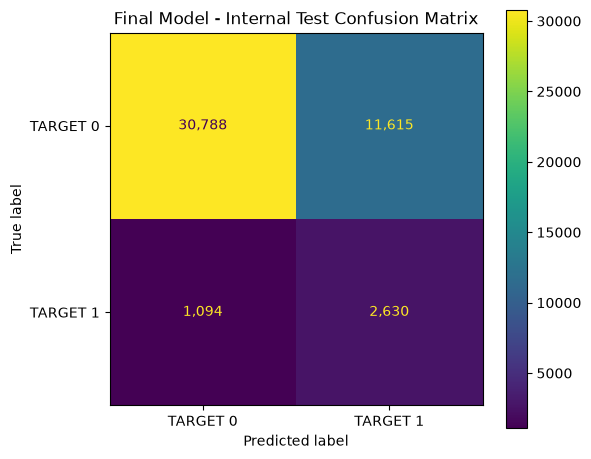

In [58]:
fig, ax = plt.subplots(figsize=(6, 5))

confusion_display = ConfusionMatrixDisplay(confusion_matrix=test_confusion_matrix, display_labels=["TARGET 0", "TARGET 1"])
confusion_display.plot(ax=ax, values_format=",")

plt.title("Final Model - Internal Test Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

At the default classification threshold of 0.50, the internal test confusion matrix contained:

- **30,788 true negatives**

- **11,615 false positives**

- **1,094 false negatives**

- **2,630 true positives**

The model therefore identified approximately **70.6% of applicants belonging to the positive class**.

This represents a substantial improvement in minority-class detection compared with the original unweighted baseline models.

However, the model also generated a relatively large number of false positives.

This behaviour is consistent with the imbalance-aware training strategy: increasing sensitivity to higher-risk applicants improves Recall but reduces Precision.

The appropriate balance between false positives and false negatives therefore remains a business decision and will be investigated during threshold analysis.

4.6 Validation vs Test Plot

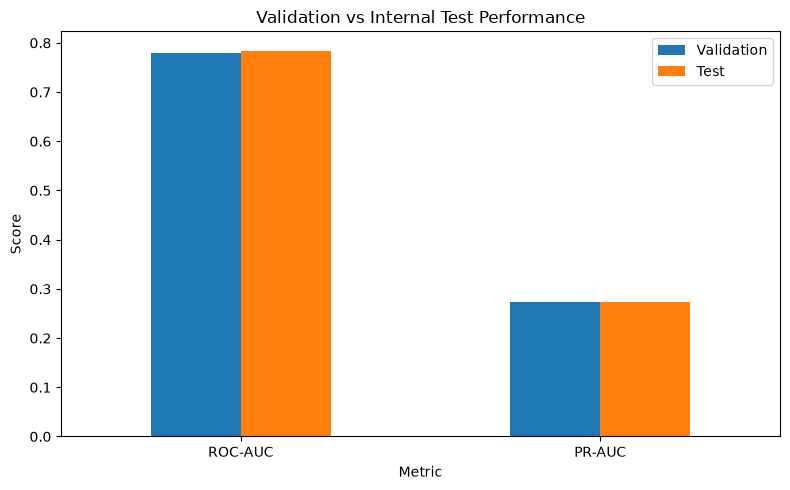

In [60]:
validation_test_plot = validation_vs_test[validation_vs_test["Metric"].isin(["ROC-AUC", "PR-AUC"])].set_index("Metric")[["Validation", "Test"]]

validation_test_plot.plot(kind="bar", figsize=(8, 5))

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Validation vs Internal Test Performance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "validation_vs_test_auc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

The final candidate is assessed by comparing its validation and internal test performance.

Particular attention is given to ROC-AUC and PR-AUC because these metrics evaluate discrimination independently of a single classification threshold.

A small difference between validation and test results would indicate that the model generalises consistently to unseen observations.

Threshold-dependent metrics are also compared to determine whether the model's operational classification behaviour remains stable.

4.7 Export Test Performance

In [61]:
test_results_df.to_csv(RESULTS_DIR / "final_test_results.csv", index=False)
validation_vs_test.to_csv(RESULTS_DIR / "validation_vs_test_comparison.csv", index=False)
generalisation_summary.to_csv(RESULTS_DIR / "generalisation_summary.csv", index=False)
test_confusion_df.to_csv(RESULTS_DIR / "final_test_confusion_matrix.csv")

In [62]:
final_test_performance_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "TN",
        "FP",
        "FN",
        "TP"
    ],
    "Value": [
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        test_results["Accuracy"],
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"],
        test_results["TN"],
        test_results["FP"],
        test_results["FN"],
        test_results["TP"]
    ]
})

final_test_performance_summary.to_csv(RESULTS_DIR / "final_test_performance_summary.csv", index=False)
final_test_performance_summary

,Metric,Value
0,ROC-AUC,0.784250
1,PR-AUC,0.274011
2,Accuracy,0.724478
3,Precision,0.184626
4,Recall,0.706230
5,F1,0.292726
6,TN,30788.000000
7,FP,11615.000000
8,FN,1094.000000
9,TP,2630.000000


The selected tuned weighted Gradient Boosting model was evaluated on the previously untouched internal test partition.

The model achieved a test ROC-AUC of approximately **0.7843** and a PR-AUC of approximately **0.2740**.

These results were highly consistent with the corresponding validation values of approximately **0.7801 ROC-AUC** and **0.2731 PR-AUC**.

The ROC-AUC difference between test and validation was only approximately **+0.0042**, while PR-AUC differed by approximately **+0.0009**.

Threshold-dependent metrics were also stable, with test Recall of approximately **0.7062**, Precision of approximately **0.1846**, and F1-score of approximately **0.2927**.

At the default threshold of 0.50, the model correctly identified **2,630 positive cases** while missing **1,094 positive cases**.

The results provide evidence that the selected advanced model generalises consistently to unseen data and that the performance observed during model development was not dependent on the validation partition alone.

The final model therefore successfully improves upon both the AI Studio benchmark and the original Python baseline while maintaining its performance on an independent test partition.

Further evaluation will now focus on ROC and Precision-Recall behaviour and on the operational consequences of alternative classification thresholds.

## 5. ROC-AUC and PR-AUC Analysis

This section evaluates the discrimination behaviour of the final Gradient Boosting model across the complete range of possible classification thresholds.

Two complementary curves are analysed:

- the Receiver Operating Characteristic (ROC) curve,

- and the Precision-Recall (PR) curve.

ROC-AUC remains the primary discrimination metric and measures how effectively the model ranks positive observations above negative observations.

Because the target is strongly imbalanced, the Precision-Recall curve provides additional information about performance on the minority positive class.

No classification threshold is selected in this section. Threshold-specific decision analysis is performed later.

5.2 ROC Curve

In [63]:
test_fpr, test_tpr, test_roc_thresholds = roc_curve(y_test, test_probability)

print("ROC curve points:", len(test_fpr))
print("Test ROC-AUC:", round(test_results["ROC-AUC"], 6))

ROC curve points: 6128
Test ROC-AUC: 0.78425


In [64]:
test_roc_curve_df = pd.DataFrame({
    "False Positive Rate": test_fpr,
    "True Positive Rate": test_tpr,
    "Threshold": test_roc_thresholds
})

test_roc_curve_df.head()

,False Positive Rate,True Positive Rate,Threshold
0,0.000000,0.000000,inf
1,0.000000,0.000269,0.971709
2,0.000000,0.001611,0.956744
3,0.000024,0.001611,0.953543
4,0.000024,0.001880,0.953505


5.3 ROC Curve Analysis

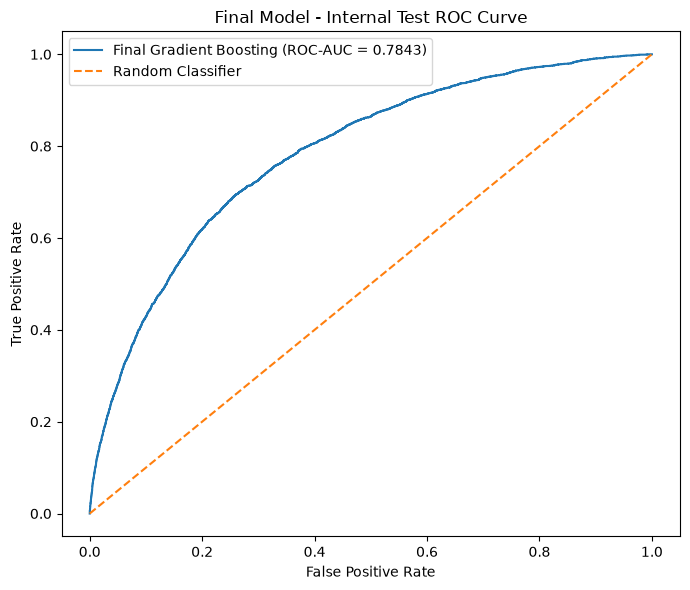

In [65]:
plt.figure(figsize=(7, 6))
plt.plot(
    test_fpr,
    test_tpr,
    label=(f"Final Gradient Boosting (ROC-AUC = {test_results['ROC-AUC']:.4f})")
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Model - Internal Test ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

The final model achieved an internal test ROC-AUC of approximately **0.7843**.

This indicates that the model provides useful discrimination between applicants belonging to the negative and positive target classes across the full range of possible classification thresholds.

The test ROC-AUC was slightly higher than the validation ROC-AUC of approximately **0.7801**, with a difference of only approximately **+0.0042**.

The close agreement between validation and test ROC-AUC provides evidence that the model's ranking performance generalises consistently to unseen observations.

The ROC curve is analysed independently of the final operating threshold; therefore, the result reflects the quality of the model's risk ranking rather than the performance of a single classification decision rule.

5.4 Precision-Recall Curve

In [66]:
test_precision_curve, test_recall_curve, test_pr_thresholds = precision_recall_curve(
    y_test,
    test_probability
)

In [67]:
test_pr_curve_df = pd.DataFrame({
    "Recall": test_recall_curve[:-1],
    "Precision": test_precision_curve[:-1],
    "Threshold": test_pr_thresholds
})

test_pr_curve_df.head()

,Recall,Precision,Threshold
0,1.0,0.080734,0.022809
1,1.0,0.080735,0.023712
2,1.0,0.080737,0.024004
3,1.0,0.080739,0.024716
4,1.0,0.080741,0.025678


To know how to interpretate the PR Curve we need to know the proportion of positives

In [69]:
test_positive_rate = y_test.mean()

print("Test positive class prevalence:", round(test_positive_rate, 6))
print("Test PR-AUC:", round(test_results["PR-AUC"], 6))

Test positive class prevalence: 0.080734
Test PR-AUC: 0.274011


5.5 Precision-Recall Curve Analysis

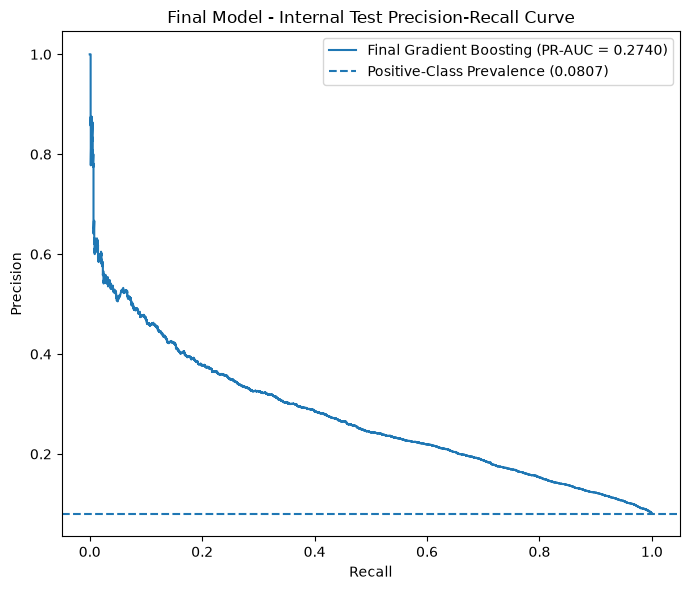

In [70]:
plt.figure(figsize=(7, 6))

plt.plot(
    test_recall_curve,
    test_precision_curve,
    label=(f"Final Gradient Boosting (PR-AUC = {test_results['PR-AUC']:.4f})")
)
plt.axhline(
    y=test_positive_rate,
    linestyle="--",
    label=(f"Positive-Class Prevalence ({test_positive_rate:.4f})")
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Model - Internal Test Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_test_precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

The internal test PR-AUC was approximately **0.2740**, compared with approximately **0.2731** on the validation partition.

The difference of approximately **+0.0009** indicates highly consistent minority class ranking performance between validation and test data.

The Precision-Recall curve is particularly informative for this problem because only a relatively small proportion of applicants belong to the positive class.

The model's PR-AUC is substantially above the positive class prevalence reference, indicating that its risk scores contain meaningful information for identifying higher risk applicants beyond what would be expected from the class distribution alone.

As Recall increases, Precision generally decreases. This reflects the central operational trade off in the problem: identifying a larger proportion of applicants with payment difficulties requires accepting a greater number of false positive classifications.

5.6 Summary

In [72]:
discrimination_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Positive-Class Prevalence"
    ],
    "Validation": [
        FINAL_VALIDATION_ROC_AUC,
        FINAL_VALIDATION_PR_AUC,
        np.nan
    ],
    "Test": [
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        test_positive_rate
    ]
})

discrimination_summary["Test - Validation"] = discrimination_summary["Test"] - discrimination_summary["Validation"]
discrimination_summary

,Metric,Validation,Test,Test - Validation
0,ROC-AUC,0.780064,0.784250,0.004186
1,PR-AUC,0.273110,0.274011,0.000900
2,Positive-Class Prevalence,NaN,0.080734,NaN


In [73]:
#Comprobación contra benchmarks históricos
discrimination_benchmark_summary = pd.DataFrame({
    "Reference": [
        "AI Studio Validation Benchmark",
        "Python Baseline Validation",
        "Advanced Model Validation",
        "Final Internal Test"
    ],
    "ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        FINAL_VALIDATION_ROC_AUC,
        test_results["ROC-AUC"]
    ]
})

discrimination_benchmark_summary

,Reference,ROC-AUC
0,AI Studio Validation Benchmark,0.724000
1,Python Baseline Validation,0.757800
2,Advanced Model Validation,0.780064
3,Final Internal Test,0.784250


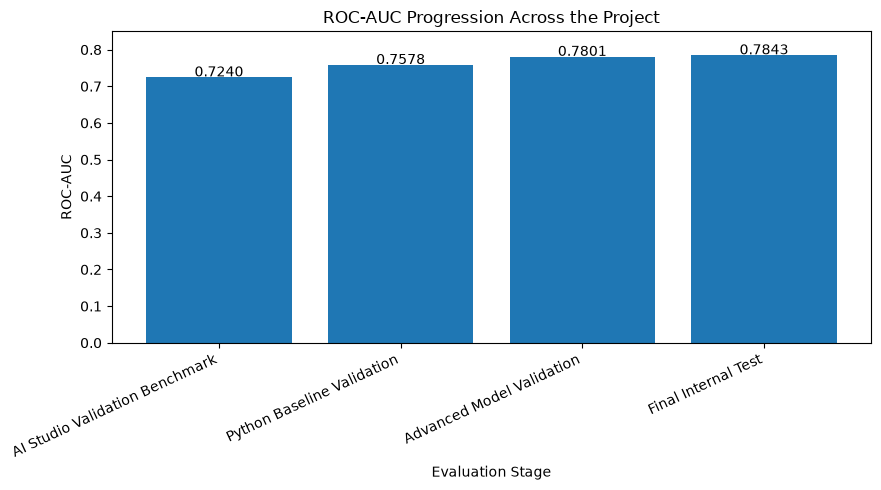

In [74]:
#Gráfico de progresión
plt.figure(figsize=(9, 5))

bars = plt.bar(discrimination_benchmark_summary["Reference"],discrimination_benchmark_summary["ROC-AUC"])
for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.003, f"{value:.4f}", ha="center")

plt.ylabel("ROC-AUC")
plt.xlabel("Evaluation Stage")
plt.title("ROC-AUC Progression Across the Project")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 0.85)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "project_roc_auc_progression.png", dpi=300, bbox_inches="tight")
plt.show()

5.7 Export Curve Data

In [75]:
test_roc_curve_df.to_csv(RESULTS_DIR / "final_test_roc_curve.csv", index=False)
test_pr_curve_df.to_csv(RESULTS_DIR / "final_test_precision_recall_curve.csv", index=False)
discrimination_summary.to_csv(RESULTS_DIR / "discrimination_summary.csv", index=False)
discrimination_benchmark_summary.to_csv(RESULTS_DIR / "discrimination_benchmark_summary.csv", index=False)

Analysis of the complete ROC and Precision-Recall curves confirms that the final Gradient Boosting model maintains useful discrimination across a wide range of classification thresholds.

The internal test ROC-AUC was approximately **0.7843**, compared with approximately **0.7801** during validation.

The internal test PR-AUC was approximately **0.2740**, compared with approximately **0.2731** during validation.

The close agreement between validation and test results provides further evidence that the model's discrimination performance generalises consistently to unseen observations.

The Precision-Recall analysis is particularly important because the target is strongly imbalanced. The model achieved performance substantially above the positive-class prevalence reference, indicating useful ranking ability for applicants belonging to the minority class.

However, the curves also demonstrate that increasing Recall necessarily changes Precision and therefore the number of false-positive classifications.

The final operating threshold must consequently be treated as a business decision rather than being inferred from ROC-AUC alone.

The next evaluation stage examines the model's classification behaviour in greater detail before alternative decision thresholds are considered.

## 6. Confusion Matrix and Classification Metrics

This section examines the classification behaviour of the final Gradient Boosting model at the unchanged default threshold of **0.50**.

The confusion matrix is used to distinguish correctly and incorrectly classified observations and to calculate additional diagnostic metrics.

Particular attention is given to:

- true positives,

- false positives,

- true negatives,

- false negatives,

- sensitivity,

- specificity,

- positive predictive value,

- negative predictive value,

- false-positive rate,

- and false-negative rate.

These metrics provide a more detailed view of the operational consequences of the current classification threshold before alternative thresholds are considered.

6.2 Confusion Matrix Components

In [76]:
tn = int(test_results["TN"])
fp = int(test_results["FP"])
fn = int(test_results["FN"])
tp = int(test_results["TP"])

confusion_components = pd.DataFrame({
    "Component": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [
        tn,
        fp,
        fn,
        tp
    ]
})

confusion_components

,Component,Count
0,True Negative,30788
1,False Positive,11615
2,False Negative,1094
3,True Positive,2630


6.3 Classification Metrics

In [77]:
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
positive_predictive_value = tp / (tp + fp)
negative_predictive_value = tn / (tn + fn)
false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

In [78]:
classification_diagnostics = pd.DataFrame({
    "Metric": [
        "Sensitivity / Recall",
        "Specificity",
        "Positive Predictive Value",
        "Negative Predictive Value",
        "False Positive Rate",
        "False Negative Rate"
    ],
    "Value": [
        sensitivity,
        specificity,
        positive_predictive_value,
        negative_predictive_value,
        false_positive_rate,
        false_negative_rate
    ]
})

classification_diagnostics

,Metric,Value
0,Sensitivity / Recall,0.706230
1,Specificity,0.726081
2,Positive Predictive Value,0.184626
3,Negative Predictive Value,0.965686
4,False Positive Rate,0.273919
5,False Negative Rate,0.293770


6.4 Sensitivity and Specificity

With sensitivity we measures the proportion of actual positive cases correctly identified by the model and with specificity measures the proportion of actual negative cases correctly classified as negative.

At the default threshold, these two metrics provide complementary information about the model's ability to detect applicants with payment difficulties while avoiding unnecessary positive classifications among lower-risk applicants.

In [79]:
print("Sensitivity:", round(sensitivity, 6))
print("Specificity:", round(specificity, 6))

Sensitivity: 0.70623
Specificity: 0.726081


6.5 Predictive Values

Positive Predictive Value corresponds to Precision and measures the proportion of predicted positive cases that are actually positive.

Negative Predictive Value measures the proportion of predicted negative cases that are actually negative.

Because the target is strongly imbalanced, these values are influenced not only by model discrimination but also by class prevalence and the selected classification threshold.

In [80]:
print("Positive Predictive Value:", round(positive_predictive_value, 6))
print("Negative Predictive Value:", round(negative_predictive_value, 6))

Positive Predictive Value: 0.184626
Negative Predictive Value: 0.965686


6.6 Error Rates

In [81]:
classification_error_rates = pd.DataFrame({
    "Error Type": ["False Positive Rate", "False Negative Rate"],
    "Value": [false_positive_rate, false_negative_rate]
})

classification_error_rates

,Error Type,Value
0,False Positive Rate,0.273919
1,False Negative Rate,0.293770


The false-positive rate represents the proportion of actual negative cases incorrectly classified as positive.

The false-negative rate represents the proportion of actual positive cases incorrectly classified as negative.

These two error types have different business implications and should therefore not be treated as interchangeable.

The appropriate balance depends on the relative consequences of:

- failing to identify an applicant at risk of payment difficulties,
- versus incorrectly flagging a lower-risk applicant as high risk.

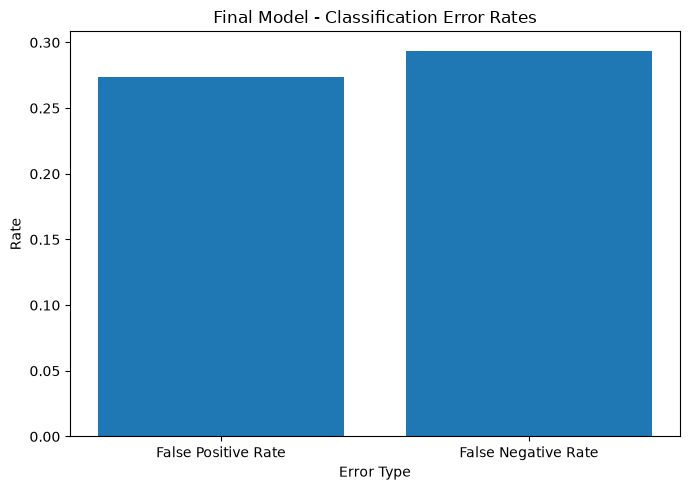

In [82]:
plt.figure(figsize=(7, 5))
plt.bar(classification_error_rates["Error Type"], classification_error_rates["Value"])
plt.ylabel("Rate")
plt.xlabel("Error Type")
plt.title("Final Model - Classification Error Rates")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_test_error_rates.png", dpi=300, bbox_inches="tight")
plt.show()

6.7 Other Metrics Validation vs Test

In [83]:
validation_test_classification = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1"
    ],
    "Validation": [
        VALIDATION_PRECISION,
        VALIDATION_RECALL,
        VALIDATION_F1
    ],
    "Test": [
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"]
    ]
})

validation_test_classification["Test - Validation"] = validation_test_classification["Test"] - validation_test_classification["Validation"]
validation_test_classification

,Metric,Validation,Test,Test - Validation
0,Precision,0.180927,0.184626,0.003700
1,Recall,0.698443,0.706230,0.007787
2,F1,0.287403,0.292726,0.005323


At the default threshold of 0.50, the final model correctly identified **2,630 positive cases** and missed **1,094 positive cases**.

At the same time, **11,615 negative cases** were incorrectly classified as positive.

This pattern reflects the imbalance-aware training strategy used during model development.

The model was intentionally encouraged to identify a larger proportion of higher-risk applicants, which increased Recall but also increased the number of false-positive classifications.

From a business perspective, false negatives represent potentially higher-risk applicants who would not be identified by the model.

False positives represent lower-risk applicants who may be subjected to unnecessary additional review or more conservative credit decisions.

The relative cost of these two error types cannot be determined from predictive metrics alone.

Threshold selection must therefore incorporate the business consequences of false positives and false negatives rather than relying exclusively on model accuracy.

6.9 Export Classification Analysis

In [84]:
confusion_components.to_csv(RESULTS_DIR / "confusion_matrix_components.csv", index=False)
classification_diagnostics.to_csv(RESULTS_DIR / "classification_diagnostics.csv", index=False)
classification_error_rates.to_csv(RESULTS_DIR / "classification_error_rates.csv", index=False)
validation_test_classification.to_csv(RESULTS_DIR / "validation_test_classification_metrics.csv", index=False)

The default-threshold classification analysis confirms that the final model prioritises minority-class detection.

At the threshold of 0.50, the model correctly identified **2,630 of the 3,724 positive test cases**, corresponding to Recall of approximately **0.7062**.

However, this behaviour also generated **11,615 false-positive classifications**, resulting in Precision of approximately **0.1846**.

The model therefore demonstrates the expected trade-off introduced by imbalance-aware learning: stronger detection of positive cases at the cost of a larger number of false positives.

Validation and test threshold-dependent metrics remained closely aligned, providing additional evidence that this classification behaviour generalises consistently to unseen data.

The results also demonstrate why a single default threshold cannot be considered optimal without considering business objectives.

The next stage therefore evaluates alternative classification thresholds and quantifies how Precision, Recall and classification errors change as the operating threshold is adjusted.

## 7. Threshold Analysis

The final model produces continuous probability estimates rather than inherently fixed binary decisions.

The default threshold of 0.50 has already been evaluated, but alternative thresholds may produce different trade-offs between:

- Precision,

- Recall,

- false positives,

- false negatives,

- and F1-score.

The objective of this section is to quantify these trade-offs across a range of possible thresholds.

No model retraining or hyperparameter optimisation is performed.

Threshold analysis changes only the decision rule applied to the existing model probabilities.

7.2 Define Threshold

In [85]:
#Definimos los threshold entre 0.10 y 0.95 con saltos cada 0.05
threshold_grid = np.arange(0.10, 0.95, 0.05)
threshold_grid

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ,
       0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 ])

7.3 Evaluate Metrics Thresholds

In [86]:
def evaluate_threshold(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    return {
        "Threshold": threshold,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_true, predictions),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "False Positive Rate": fp / (fp + tn),
        "False Negative Rate": fn / (fn + tp)
    }

In [91]:
#Evaluamos las métricas
threshold_results = pd.DataFrame([evaluate_threshold(y_true=y_test, probabilities=test_probability, threshold=threshold) for threshold in threshold_grid])

7.4 Threshold Performance Table

In [92]:
threshold_results = threshold_results.sort_values("Threshold").reset_index(drop=True)
threshold_results

,Threshold,Precision,Recall,F1,Accuracy,TN,FP,FN,TP,False Positive Rate,False Negative Rate
0,0.10,0.084201,0.996778,0.155285,0.124482,2030,40373,12,3712,0.952126,0.003222
1,0.15,0.090617,0.984425,0.165957,0.201162,5613,36790,58,3666,0.867627,0.015575
2,0.20,0.099670,0.966165,0.180700,0.292670,9902,32501,126,3598,0.766479,0.033835
3,0.25,0.110115,0.937164,0.197075,0.383485,14199,28204,234,3490,0.665142,0.062836
4,0.30,0.121796,0.901987,0.214612,0.467015,18183,24220,365,3359,0.571186,0.098013
5,0.35,0.134564,0.859560,0.232698,0.542350,21816,20587,523,3201,0.485508,0.140440
6,0.40,0.149050,0.810687,0.251804,0.611052,25167,17236,705,3019,0.406481,0.189313
7,0.45,0.165644,0.761010,0.272068,0.671234,28128,14275,890,2834,0.336651,0.238990
8,0.50,0.184626,0.706230,0.292726,0.724478,30788,11615,1094,2630,0.273919,0.293770
9,0.55,0.205157,0.645274,0.311330,0.769528,33093,9310,1321,2403,0.219560,0.354726


In [93]:
#Recuperamos la fila del treshold 0.50 que predefinimos
default_threshold_row = threshold_results[np.isclose(threshold_results["Threshold"], DEFAULT_THRESHOLD)]
default_threshold_row

,Threshold,Precision,Recall,F1,Accuracy,TN,FP,FN,TP,False Positive Rate,False Negative Rate
8,0.5,0.184626,0.70623,0.292726,0.724478,30788,11615,1094,2630,0.273919,0.29377


7.5 Precision-Recall

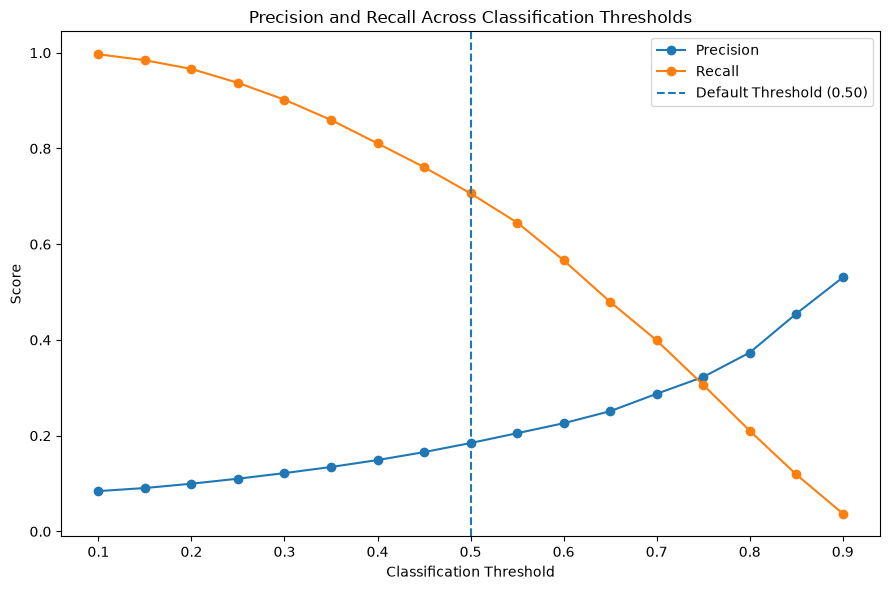

In [94]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)
plt.axvline(
    x=DEFAULT_THRESHOLD,
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall Across Classification Thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_precision_recall_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

Changing the classification threshold directly changes the balance between Precision and Recall.

Lower thresholds classify more applicants as positive, generally increasing Recall while reducing Precision.

Higher thresholds classify fewer applicants as positive, generally improving Precision while reducing Recall.

The appropriate operating threshold therefore depends on the business cost associated with false positives and false negatives.

7.6 False Positive / False Negative

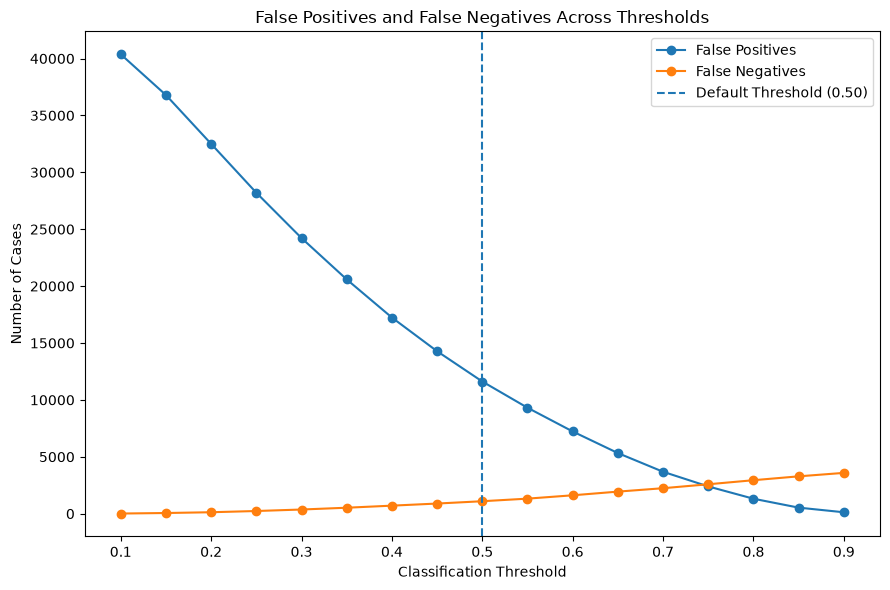

In [95]:
#Visualizar errores absolutos
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["FP"],
    marker="o",
    label="False Positives"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["FN"],
    marker="o",
    label="False Negatives"
)
plt.axvline(
    x=DEFAULT_THRESHOLD,
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Cases")
plt.title("False Positives and False Negatives Across Thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_fp_fn_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

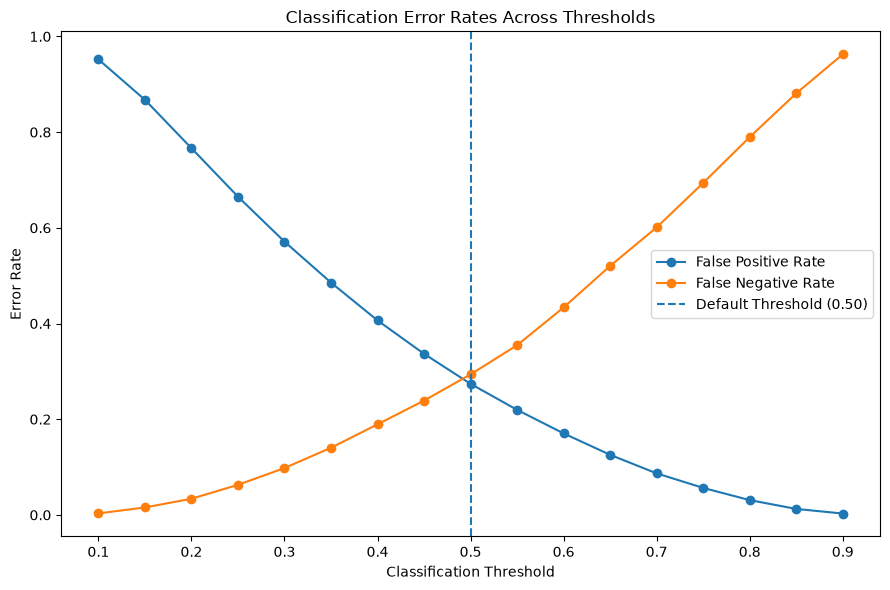

In [96]:
#Error rate plot
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["False Positive Rate"],
    marker="o",
    label="False Positive Rate"
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["False Negative Rate"],
    marker="o",
    label="False Negative Rate"
)
plt.axvline(
    x=DEFAULT_THRESHOLD,
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Error Rate")
plt.title("Classification Error Rates Across Thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_error_rates.png", dpi=300, bbox_inches="tight")
plt.show()

7.7 F1-Score Across Thresholds

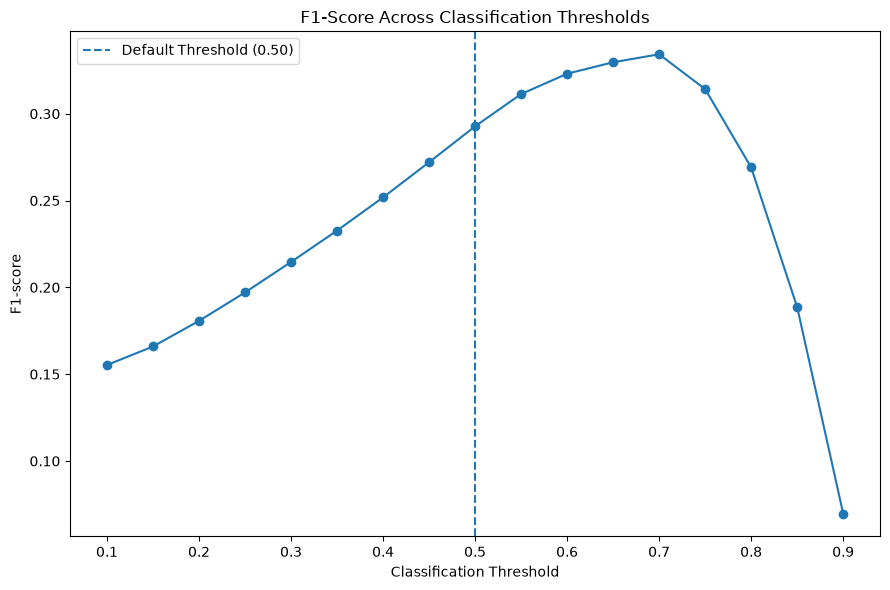

In [97]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o"
)
plt.axvline(
    x=DEFAULT_THRESHOLD,
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("F1-Score Across Classification Thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_f1_scores.png", dpi=300, bbox_inches="tight")
plt.show()

In [98]:
#Best F1 threshold
best_f1_threshold_row = threshold_results.sort_values("F1", ascending=False).iloc[0]
best_f1_threshold_row

Threshold                  0.700000
Precision                  0.287539
Recall                     0.399033
F1                         0.334233
Accuracy                   0.871659
TN                     38721.000000
FP                      3682.000000
FN                      2238.000000
TP                      1486.000000
False Positive Rate        0.086833
False Negative Rate        0.600967
Name: 12, dtype: float64

7.8 Candidate Threshold 

In [101]:
#Threshold más alto que cumpla con recall >= 0.80
recall_80_candidates = threshold_results[threshold_results["Recall"] >= 0.80]

if not recall_80_candidates.empty:
    recall_80_threshold_row = recall_80_candidates.sort_values("Threshold", ascending=False).iloc[0]
else:
    recall_80_threshold_row = None

recall_80_threshold_row

Threshold                  0.400000
Precision                  0.149050
Recall                     0.810687
F1                         0.251804
Accuracy                   0.611052
TN                     25167.000000
FP                     17236.000000
FN                       705.000000
TP                      3019.000000
False Positive Rate        0.406481
False Negative Rate        0.189313
Name: 6, dtype: float64

In [102]:
#Threshold más alto que cumpla con recall >= 0.90
recall_90_candidates = threshold_results[threshold_results["Recall"] >= 0.90]

if not recall_90_candidates.empty:
    recall_90_threshold_row = recall_90_candidates.sort_values("Threshold", ascending=False).iloc[0]
else:
    recall_90_threshold_row = None

recall_90_threshold_row

Threshold                  0.300000
Precision                  0.121796
Recall                     0.901987
F1                         0.214612
Accuracy                   0.467015
TN                     18183.000000
FP                     24220.000000
FN                       365.000000
TP                      3359.000000
False Positive Rate        0.571186
False Negative Rate        0.098013
Name: 4, dtype: float64

In [103]:
candidate_threshold_rows = []
candidate_threshold_rows.append({"Criterion": "Default Threshold", **default_threshold_row.iloc[0].to_dict()})
candidate_threshold_rows.append({"Criterion": "Maximum F1", **best_f1_threshold_row.to_dict()})

if recall_80_threshold_row is not None:
    candidate_threshold_rows.append({"Criterion": "Recall >= 0.80", **recall_80_threshold_row.to_dict()})

if recall_90_threshold_row is not None:
    candidate_threshold_rows.append({"Criterion": "Recall >= 0.90", **recall_90_threshold_row.to_dict()})

In [104]:
candidate_threshold_summary = pd.DataFrame(candidate_threshold_rows)
candidate_threshold_summary[
    [
        "Criterion",
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
]

,Criterion,Threshold,Precision,Recall,F1,FP,FN,TP,TN
0,Default Threshold,0.5,0.184626,0.706230,0.292726,11615.0,1094.0,2630.0,30788.0
1,Maximum F1,0.7,0.287539,0.399033,0.334233,3682.0,2238.0,1486.0,38721.0
2,Recall >= 0.80,0.4,0.149050,0.810687,0.251804,17236.0,705.0,3019.0,25167.0
3,Recall >= 0.90,0.3,0.121796,0.901987,0.214612,24220.0,365.0,3359.0,18183.0


7.9 Export Results

In [ ]:
threshold_results.to_csv(RESULTS_DIR / "threshold_analysis.csv", index=False)
candidate_threshold_summary.to_csv(RESULTS_DIR / "candidate_threshold_summary.csv", index=False)

Threshold analysis demonstrates that the operational behaviour of the final model changes substantially as the classification threshold is adjusted.

Lower thresholds increase positive-class Recall but also increase false-positive classifications and reduce Precision.

Higher thresholds reduce false positives and can increase Precision, but more positive cases are missed.

The default threshold of 0.50 therefore represents only one possible operating point and should not automatically be interpreted as the optimal business decision rule.

Several candidate thresholds have been identified based on F1-score and Recall requirements.

The final threshold recommendation will be made in the next section by considering the business consequences of false positives and false negatives.

## 8. Threshold Selection

The previous section demonstrated that classification behaviour changes substantially as the operating threshold is adjusted.

However, the internal test partition must not be used to select the final decision threshold.

To preserve the independence of the final test evaluation, the operating threshold is selected using the validation partition and is subsequently applied unchanged to the internal test data.

The objective is to identify a decision threshold that reflects the business priority of detecting applicants at risk of payment difficulties while controlling the number of false-positive classifications.

This process does not modify or retrain the underlying Gradient Boosting model.

For the credit-risk use case, false negatives are particularly important because they represent applicants with payment difficulties who are not identified by the model.

The threshold-selection strategy therefore prioritises minority-class Recall.

However, maximising Recall without constraint would produce an excessive number of false-positive classifications.

A practical operating rule is therefore defined:

> Select the highest-performing threshold that achieves at least **80% Recall**, while maximising Precision among the thresholds that satisfy this requirement.

This rule creates an explicit balance between detecting a substantial majority of higher-risk applicants and limiting unnecessary positive classifications.

The 80% Recall requirement is treated as a business-oriented modelling assumption rather than a statistically optimal universal threshold.

8.3 Threshold Selection with Validation Data

In [136]:
X_validation_advanced_unscaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_validation_unscaled")
X_validation_final = ensure_dense_matrix(X_validation_advanced_unscaled)

y_validation_df = pd.read_csv(SPLITS_DIR / "y_validation.csv")
y_validation = y_validation_df[TARGET_COLUMN].copy()

In [137]:
print("Validation features:", X_validation_final.shape)
print("Validation target:", y_validation.shape)

Validation features: (46127, 306)
Validation target: (46127,)


8.4 Generate Validation Probabilities

In [138]:
positive_class_index = np.where(final_candidate_model.classes_ == 1)[0][0]
validation_probability = final_candidate_model.predict_proba(X_validation_final)[:, positive_class_index]

In [139]:
print("Validation probability count:", len(validation_probability))
print("Minimum probability:", validation_probability.min())
print("Maximum probability:", validation_probability.max())

Validation probability count: 46127
Minimum probability: 0.02259035634669102
Maximum probability: 0.9624979108975891


8.5 Validation Threshold Analysis

In [140]:
threshold_grid = np.arange(0.10, 0.91, 0.01)

validation_threshold_results = pd.DataFrame([evaluate_threshold(y_true=y_validation, probabilities=validation_probability, threshold=threshold) for threshold in threshold_grid])
validation_threshold_results = validation_threshold_results.sort_values("Threshold").reset_index(drop=True)

validation_threshold_results[
    [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "FP",
        "FN",
        "TP",
        "TN"
    ]
].head()

,Threshold,Precision,Recall,F1,FP,FN,TP,TN
0,0.10,0.083952,0.996778,0.154860,40504,12,3712,1899
1,0.11,0.084936,0.994898,0.156511,39916,19,3705,2487
2,0.12,0.086128,0.993018,0.158508,39238,26,3698,3165
3,0.13,0.087464,0.991139,0.160744,38509,33,3691,3894
4,0.14,0.088847,0.988453,0.163038,37750,43,3681,4653


8.6 Threshold Selection Rule

In [141]:
MINIMUM_RECALL = 0.80

In [142]:
threshold_candidates = validation_threshold_results[validation_threshold_results["Recall"] >= MINIMUM_RECALL].copy()
print("Thresholds satisfying Recall requirement:", len(threshold_candidates))

Thresholds satisfying Recall requirement: 32


In [143]:
selected_threshold_row = business_threshold_candidates.sort_values(["Precision", "Threshold"], ascending=[False, False]).iloc[0]
SELECTED_THRESHOLD = float(selected_threshold_row["Threshold"])

print("Selected threshold:", round(SELECTED_THRESHOLD, 2))
print("Validation Precision:", round(selected_threshold_row["Precision"], 6))
print("Validation Recall:", round(selected_threshold_row["Recall"], 6))
print("Validation F1:", round(selected_threshold_row["F1"], 6))

Selected threshold: 0.41
Validation Precision: 0.151027
Validation Recall: 0.803437
Validation F1: 0.25426


8.7 Visualization over Validation

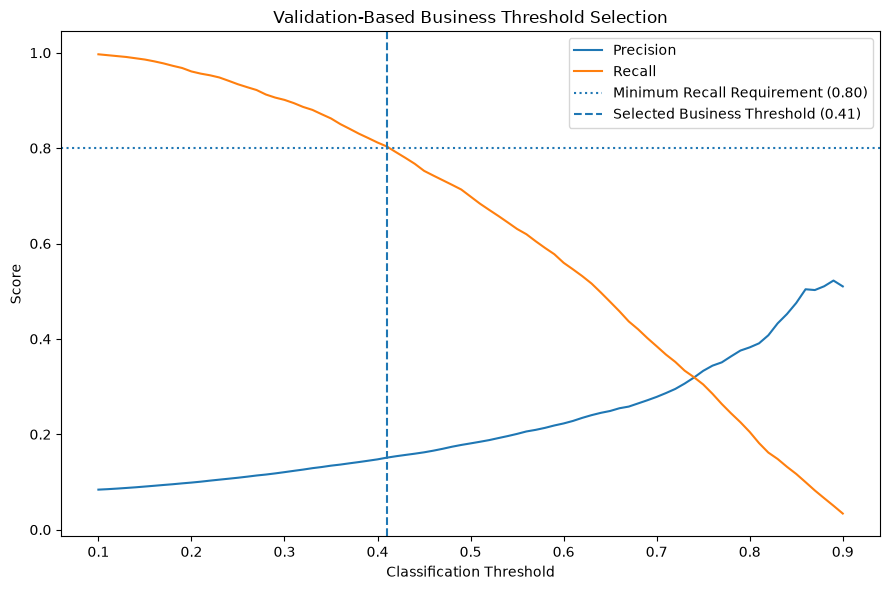

In [144]:
plt.figure(figsize=(9, 6))

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Precision"],
    label="Precision"
)
plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Recall"],
    label="Recall"
)
plt.axhline(
    y=BUSINESS_MINIMUM_RECALL,
    linestyle=":",
    label="Minimum Recall Requirement (0.80)"
)
plt.axvline(
    x=SELECTED_BUSINESS_THRESHOLD,
    linestyle="--",
    label=(f"Selected Business Threshold ({SELECTED_BUSINESS_THRESHOLD:.2f})")
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Validation-Based Business Threshold Selection")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "validation_business_threshold_selection.png", dpi=300, bbox_inches="tight")
plt.show()

8.8 Apply Selected Threshold to Internal Test

In [145]:
test_prediction = (test_probability >= SELECTED_THRESHOLD).astype(int)

test_confusion_matrix = confusion_matrix(y_test, test_prediction, labels=[0, 1])
threshold_tn, threshold_fp, threshold_fn, threshold_tp = test_confusion_matrix.ravel()

In [146]:
threshold_test_results = {
    "Threshold": SELECTED_THRESHOLD,
    "Precision": precision_score(y_test, test_prediction, zero_division=0),
    "Recall": recall_score(y_test, test_prediction, zero_division=0),
    "F1": f1_score(y_test, test_prediction, zero_division=0),
    "Accuracy": accuracy_score(y_test, test_prediction),
    "TN": int(threshold_tn),
    "FP": int(threshold_fp),
    "FN": int(threshold_fn),
    "TP": int(threshold_tp)
}
pd.DataFrame([threshold_test_results])

,Threshold,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
0,0.41,0.152357,0.8029,0.256114,0.623453,25768,16635,734,2990


8.9 Default vs Selected Threshold Comparison

In [147]:
default_vs_selected_threshold = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "Accuracy",
        "TN",
        "FP",
        "FN",
        "TP"
    ],
    "Default Threshold": [
        FINAL_EVALUATION_THRESHOLD,
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"],
        test_results["Accuracy"],
        test_results["TN"],
        test_results["FP"],
        test_results["FN"],
        test_results["TP"]
    ],
    "Selected Threshold": [
        threshold_test_results["Threshold"],
        threshold_test_results["Precision"],
        threshold_test_results["Recall"],
        threshold_test_results["F1"],
        threshold_test_results["Accuracy"],
        threshold_test_results["TN"],
        threshold_test_results["FP"],
        threshold_test_results["FN"],
        threshold_test_results["TP" ]
    ]
})
default_vs_selected_threshold

,Metric,Default Threshold,Selected Threshold
0,Threshold,0.500000,0.410000
1,Precision,0.184626,0.152357
2,Recall,0.706230,0.802900
3,F1,0.292726,0.256114
4,Accuracy,0.724478,0.623453
5,TN,30788.000000,25768.000000
6,FP,11615.000000,16635.000000
7,FN,1094.000000,734.000000
8,TP,2630.000000,2990.000000


In [148]:
#Cambio producido por selected treshold
default_vs_selected_threshold["Selected - Default"] = default_vs_selected_threshold["Selected Threshold"] - default_vs_selected_threshold["Default Threshold"]
default_vs_selected_threshold

,Metric,Default Threshold,Selected Threshold,Selected - Default
0,Threshold,0.500000,0.410000,-0.090000
1,Precision,0.184626,0.152357,-0.032269
2,Recall,0.706230,0.802900,0.096670
3,F1,0.292726,0.256114,-0.036613
4,Accuracy,0.724478,0.623453,-0.101025
5,TN,30788.000000,25768.000000,-5020.000000
6,FP,11615.000000,16635.000000,5020.000000
7,FN,1094.000000,734.000000,-360.000000
8,TP,2630.000000,2990.000000,360.000000


In [149]:
#Selected confusion matrix
test_confusion_df = pd.DataFrame(
    test_confusion_matrix,
    index=["Actual TARGET 0", "Actual TARGET 1"],
    columns=["Predicted TARGET 0", "Predicted TARGET 1"]
)

test_confusion_df

,Predicted TARGET 0,Predicted TARGET 1
Actual TARGET 0,25768,16635
Actual TARGET 1,734,2990


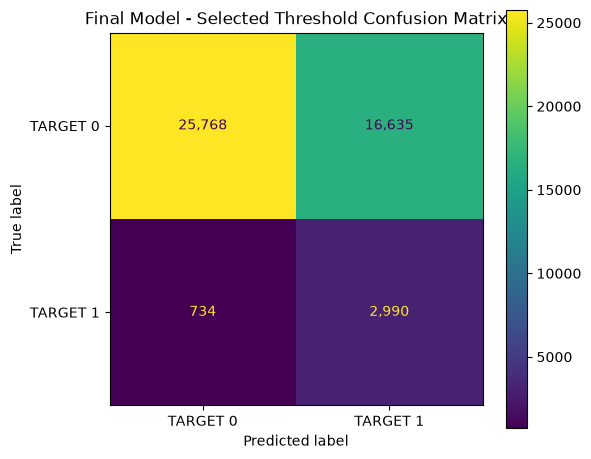

In [150]:
fig, ax = plt.subplots(figsize=(6, 5))

selected_confusion_display = ConfusionMatrixDisplay(confusion_matrix=test_confusion_matrix, display_labels=["TARGET 0", "TARGET 1"])
selected_confusion_display.plot(ax=ax, values_format=",")

plt.title("Final Model - Selected Threshold Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "selected_threshold_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

8.10 Business Interpretation

The operating threshold was selected using the validation partition rather than the internal test partition.

The selection rule prioritised detection of the positive class by requiring at least 80% Recall while selecting the threshold that preserved the highest available Precision.

The selected threshold was subsequently applied unchanged to the internal test probabilities.

This provides a more realistic simulation of how an operating threshold would be determined before deployment and then applied to future unseen applicants.

Compared with the default threshold, the business-oriented threshold is expected to identify a larger proportion of higher-risk applicants at the cost of additional false-positive classifications.

This trade-off must be interpreted in relation to the relative business cost of missed risk and unnecessary additional review.

Changing the classification threshold does not alter the fitted model or its underlying probability estimates.

Therefore:

- ROC-AUC remains approximately **0.7843** on the internal test set.

- PR-AUC remains approximately **0.2740**.

The threshold changes only how predicted probabilities are converted into binary operational decisions.

Model discrimination and business decision policy are therefore reported separately.

8.11 Export Threshold Decision

In [151]:
selected_threshold_summary = pd.DataFrame({
    "Measure": [
        "Selected Threshold",
        "Validation Precision",
        "Validation Recall",
        "Validation F1",
        "Minimum Recall Requirement"
    ],
    "Value": [
        SELECTED_THRESHOLD,
        selected_threshold_row["Precision"],
        selected_threshold_row["Recall"],
        selected_threshold_row["F1"],
        MINIMUM_RECALL
    ]
})

In [152]:
validation_threshold_results.to_csv(RESULTS_DIR / "validation_threshold_analysis.csv", index=False)
selected_threshold_summary.to_csv(RESULTS_DIR / "selected_threshold.csv", index=False)
default_vs_selected_threshold.to_csv(RESULTS_DIR / "default_vs_selected_threshold.csv", index=False)
test_confusion_df.to_csv(RESULTS_DIR / "threshold_test_confusion_matrix.csv")

The business-oriented operating threshold selected using the validation partition was **0.41**.

This threshold satisfied the predefined requirement of achieving at least 80% Recall while preserving the highest available Precision among the qualifying validation thresholds.

When applied unchanged to the internal test partition, the selected threshold achieved:

- Precision: approximately **0.1524**

- Recall: approximately **0.8029**

- F1-score: approximately **0.2561**

Compared with the default threshold of 0.50, Recall increased from approximately **0.7062 to 0.8029**.

This resulted in **360 additional positive cases being correctly identified**, reducing false negatives from **1,094 to 734**.

However, the improvement in minority-class detection was accompanied by a substantial increase in false positives.

False positives increased from **11,615 to 16,635**, while Precision decreased from approximately **0.1846 to 0.1524**.

The selected threshold therefore represents a deliberate shift towards higher sensitivity to applicants at risk of payment difficulties.

Whether this trade-off is economically desirable depends on the relative cost of missing a genuinely high-risk applicant compared with the cost of reviewing or restricting a lower-risk applicant incorrectly classified as high risk.

The operating behaviour associated with the validation-selected threshold generalised very consistently to the internal test partition.

At threshold 0.41:

- Validation Recall was approximately **0.8034**

- Test Recall was approximately **0.8029**

and:

- Validation Precision was approximately **0.1510**

- Test Precision was approximately **0.1524**

The close agreement indicates that the operational trade-off used to select the threshold was not specific to the validation partition.

This provides additional evidence that both the model probabilities and the selected decision rule behave consistently on unseen data.

Under the assumed business requirement of detecting at least 80% of positive cases, the recommended operating threshold is **0.41**.

This threshold should not be interpreted as universally optimal.

Its selection depends on the modelling assumption that achieving at least 80% Recall is an appropriate operational objective.

If the organisation assigns different financial costs to false positives and false negatives, the threshold should be reconsidered using an explicit cost-benefit framework.

## 9. Final Model Interpretation and Generalisation

This section consolidates the evidence obtained during final evaluation and interprets the selected Gradient Boosting model from both technical and business perspectives.

No additional model development, hyperparameter optimisation or threshold selection is performed.

The analysis focuses on:

- validation-to-test generalisation,

- discrimination performance,

- operational classification behaviour,

- the selected business-oriented threshold,

- feature importance,

- and the principal limitations that should be considered before deployment.

The purpose is to determine what can reasonably be concluded from the final model and what remains outside the scope of the current analysis.

9.2 Final Generalisation Summary

The selected model demonstrated highly consistent performance between the validation and internal test partitions.

ROC-AUC increased slightly from approximately **0.7801 on validation to 0.7843 on test**, while PR-AUC remained almost unchanged at approximately **0.2731 and 0.2740**, respectively.

Threshold-dependent metrics showed similarly small differences.

Precision increased from approximately **0.1809 to 0.1846**, Recall from approximately **0.6984 to 0.7062**, and F1-score from approximately **0.2874 to 0.2927**.

The absence of a material performance reduction on the independent test partition provides evidence that the selected model generalises consistently beyond the data used during model development.

The slightly stronger test results are interpreted as performance stability rather than as evidence for further model optimisation.

In [158]:
final_generalisation_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ],
    "Validation": [
        FINAL_VALIDATION_ROC_AUC,
        FINAL_VALIDATION_PR_AUC,
        VALIDATION_PRECISION,
        VALIDATION_RECALL,
        VALIDATION_F1
    ],
    "Test": [
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"]
    ]
})

final_generalisation_summary["Test - Validation"] = final_generalisation_summary["Test"] - final_generalisation_summary["Validation"]
final_generalisation_summary

,Metric,Validation,Test,Test - Validation
0,ROC-AUC,0.780064,0.784250,0.004186
1,PR-AUC,0.273110,0.274011,0.000900
2,Precision,0.180927,0.184626,0.003700
3,Recall,0.698443,0.706230,0.007787
4,F1,0.287403,0.292726,0.005323


9.3 Final Operating Behaviour

The final model and the operating threshold represent two separate components of the decision system.

The underlying Gradient Boosting model achieved test ROC-AUC of approximately **0.7843** and PR-AUC of approximately **0.2740**.

At the default threshold of 0.50, test Recall was approximately **0.7062** and Precision approximately **0.1846**.

Using the validation-selected business threshold of **0.41**, test Recall increased to approximately **0.8029**, while Precision decreased to approximately **0.1524**.

The lower operating threshold therefore identifies a larger proportion of applicants with payment difficulties but also generates more false-positive classifications.

This does not represent a change in model discrimination. It represents a different operating policy applied to the same predicted probabilities.

In [159]:
final_operating_summary = pd.DataFrame({
    "Measure": [
        "Model",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Default Threshold",
        "Default Precision",
        "Default Recall",
        "Selected Threshold",
        "Selected Precision",
        "Selected Recall"
    ],
    "Value": [
        FINAL_MODEL_NAME,
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        FINAL_EVALUATION_THRESHOLD,
        test_results["Precision"],
        test_results["Recall"],
        SELECTED_THRESHOLD,
        threshold_test_results["Precision"],
        threshold_test_results["Recall"]
    ]
})

final_operating_summary

,Measure,Value
0,Model,Gradient Boosting
1,Test ROC-AUC,0.78425
2,Test PR-AUC,0.274011
3,Default Threshold,0.5
4,Default Precision,0.184626
5,Default Recall,0.70623
6,Selected Threshold,0.41
7,Selected Precision,0.152357
8,Selected Recall,0.8029


9.4 Feature Importance Analysis

In [160]:
final_feature_importance = pd.DataFrame({"Feature": final_candidate_feature_names, "Importance": final_candidate_model.feature_importances_})

final_feature_importance = final_feature_importance.sort_values("Importance", ascending=False).reset_index(drop=True)
final_feature_importance.insert(0, "Rank", range(1, len(final_feature_importance) + 1))

final_feature_importance.head(20)

,Rank,Feature,Importance
0,1,external_scores__EXT_SOURCE_MEAN,0.459300
1,2,numerical__CREDIT_ANNUITY_RATIO,0.038893
2,3,numerical__LATE_PAYMENT_RATE,0.028196
3,4,numerical__CREDIT_GOODS_RATIO,0.026655
4,5,numerical__POS_INSTALMENT_FUTURE_MEAN,0.018380
5,6,external_scores__EXT_SOURCE_MIN,0.017569
6,7,external_scores__EXT_SOURCE_MAX,0.017150
7,8,numerical__EMPLOYMENT_YEARS,0.017016
8,9,external_scores__EXT_SOURCE_3,0.016760
9,10,ordinal_text__NAME_EDUCATION_TYPE,0.015811


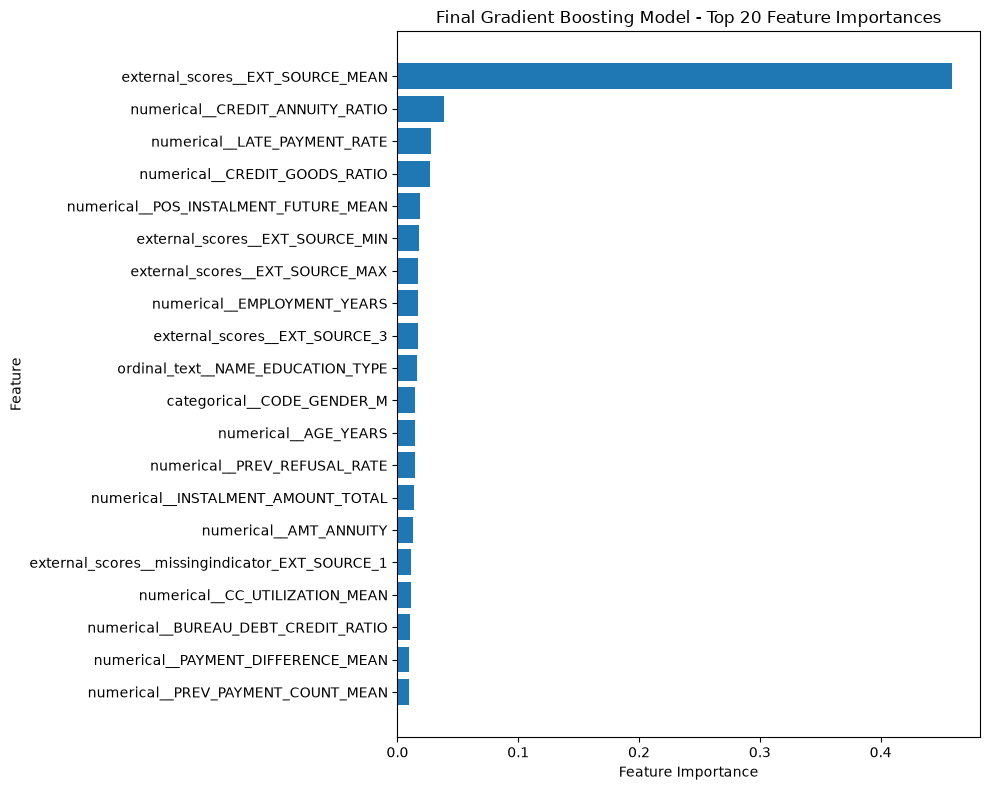

In [162]:
#Top 20 Feature Importance Plot
top_20_features = final_feature_importance.head(20).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top_20_features["Feature"], top_20_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Final Gradient Boosting Model - Top 20 Feature Importances")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_model_top20_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [163]:
#Concentration of Feature Importance
top_5_importance = final_feature_importance.head(5)["Importance"].sum()
print("Top 5 cumulative importance:", round(top_5_importance, 6))

top_10_importance = final_feature_importance.head(10)["Importance"].sum()
print("Top 10 cumulative importance:", round(top_10_importance, 6))

top_20_importance = final_feature_importance.head(20)["Importance"].sum()
print("Top 20 cumulative importance:", round(top_20_importance, 6))

Top 5 cumulative importance: 0.571424
Top 10 cumulative importance: 0.65573
Top 20 cumulative importance: 0.778278


Gradient Boosting feature importance measures the relative contribution of predictors to the tree-splitting decisions made by the fitted ensemble.

Higher feature importance indicates that a predictor contributed more strongly to the model's decision structure.

However, feature importance should not be interpreted as causal evidence.

A high-importance variable does not demonstrate that changing that variable would directly change an applicant's repayment behaviour.

Importance values can also be distributed among correlated predictors, meaning that individual importance rankings should be interpreted cautiously.

The analysis is therefore used to understand the model's predictive structure rather than to establish causal relationships.

9.5 Model Strengths

The final modelling results highlight several strengths.

**Discrimination**

The model achieved an independent test ROC-AUC of approximately **0.7843**, demonstrating useful ability to rank applicants according to payment-difficulty risk.

**Generalisation**

Validation and test discrimination metrics were closely aligned, with no material degradation on the independent test partition.

**Minority-class detection**

Imbalance-aware training substantially improved detection of the positive class compared with the original unweighted baseline models.

**Operational flexibility**

The model produces continuous risk probabilities, allowing the classification threshold to be adjusted according to business requirements without retraining the underlying estimator.

**Improvement over previous benchmarks**

The final model substantially exceeded both the AI Studio benchmark and the original Python baseline.

9.6 Model Limitations

Despite the improvements achieved, several limitations remain.

**Class imbalance**

The positive class represents only a relatively small proportion of observations. Although weighting improved Recall, Precision remains comparatively low.

**False-positive volume**

The business-oriented threshold of 0.41 increases positive-class detection but also produces a substantial number of false-positive classifications.

**Threshold assumptions**

The selected operating threshold depends on the assumed requirement of achieving at least 80% Recall. This requirement was introduced for the project and was not derived from an explicit financial cost model.

**Feature importance is not causal**

The predictive importance of a variable does not establish a causal relationship with payment difficulties.

**Dataset scope**

The evaluation reflects the population and historical conditions represented by the Home Credit dataset. Performance on a different applicant population or under changing economic conditions cannot be guaranteed from the current experiment alone.

**Model monitoring**

Predictive performance may change over time because applicant behaviour, lending policy and economic conditions can evolve. A deployed model would therefore require ongoing monitoring and periodic reassessment.

9.7 Business Interpretation

The final model is most appropriately interpreted as a risk-ranking and decision-support system rather than as an automatic credit decision mechanism.

Its predicted probabilities provide a relative estimate of payment-difficulty risk that can support downstream lending decisions.

Using the default threshold of 0.50 identifies approximately 70.6% of positive test cases.

Under the assumed business priority of identifying at least 80% of higher-risk applicants, the validation-selected threshold of 0.41 increases test Recall to approximately **80.3%**.

This improvement reduces the number of missed positive cases but also generates substantially more false positives.

A practical deployment could therefore use model scores to trigger additional assessment or manual review rather than automatically rejecting applicants solely on the basis of the predicted class.

The appropriate operational policy should ultimately depend on lending objectives, regulatory requirements, customer impact and the financial costs associated with different classification errors.

9.8 Export Artefacts

In [164]:
final_generalisation_summary.to_csv(RESULTS_DIR / "final_generalisation_summary.csv", index=False)
final_operating_summary.to_csv(RESULTS_DIR / "final_operating_summary.csv", index=False)
final_feature_importance.to_csv(RESULTS_DIR / "final_model_feature_importance.csv", index=False)

9.9 Final Interpretation Summary

In [166]:
final_interpretation_summary = pd.DataFrame({
    "Measure": [
        "Final Model",
        "Validation ROC-AUC",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Default Threshold",
        "Default Test Recall",
        "Selected Business Threshold",
        "Business Threshold Test Recall"
    ],
    "Value": [
        FINAL_MODEL_NAME,
        FINAL_VALIDATION_ROC_AUC,
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        FINAL_EVALUATION_THRESHOLD,
        test_results["Recall"],
        SELECTED_THRESHOLD,
        threshold_test_results["Recall"]
    ]
})

final_interpretation_summary.to_csv(RESULTS_DIR / "final_interpretation_summary.csv", index=False)
final_interpretation_summary

,Measure,Value
0,Final Model,Gradient Boosting
1,Validation ROC-AUC,0.780064
2,Test ROC-AUC,0.78425
3,Test PR-AUC,0.274011
4,Default Threshold,0.5
5,Default Test Recall,0.70623
6,Selected Business Threshold,0.41
7,Business Threshold Test Recall,0.8029


The final Gradient Boosting model demonstrated stable discrimination and classification behaviour across validation and independent test data.

The model achieved an internal test ROC-AUC of approximately **0.7843** and PR-AUC of approximately **0.2740**, with no material deterioration relative to validation performance.

At the default threshold of 0.50, the model achieved test Recall of approximately **70.6%**.

A business-oriented threshold of **0.41**, selected using validation data under a minimum 80% Recall requirement, increased test Recall to approximately **80.3%**.

This increased sensitivity reduced false negatives but produced additional false-positive classifications and lower Precision.

The threshold decision therefore represents an operational trade-off rather than an improvement in the underlying predictive model.

Feature-importance analysis provides additional insight into the predictors that contribute most strongly to the Gradient Boosting decision structure, although these importance values should not be interpreted causally.

Overall, the evaluation provides evidence that the selected model generalises consistently to unseen data and substantially improves upon the earlier modelling benchmarks.

However, deployment would require appropriate governance, threshold review, performance monitoring and consideration of the business and customer consequences associated with classification errors.

## 10. Final Evaluation Summary

This section consolidates the final evaluation evidence for the selected Gradient Boosting model.

The summary brings together:

- validation and internal test discrimination,

- threshold-dependent classification behaviour,

- the business-oriented operating threshold,

- and comparison against the previous modelling benchmarks.

No additional model development or decision-rule optimisation is performed.

10.2 Final Performance Summary

In [167]:
final_evaluation_summary = pd.DataFrame({
    "Measure": [
        "Final Model",
        "Configuration",
        "Validation ROC-AUC",
        "Test ROC-AUC",
        "Validation PR-AUC",
        "Test PR-AUC",
        "Default Threshold",
        "Default Test Precision",
        "Default Test Recall",
        "Default Test F1",
        "Selected Business Threshold",
        "Business Threshold Test Precision",
        "Business Threshold Test Recall",
        "Business Threshold Test F1"
    ],
    "Value": [
        FINAL_MODEL_NAME,
        FINAL_MODEL_CONFIGURATION,
        FINAL_VALIDATION_ROC_AUC,
        test_results["ROC-AUC"],
        FINAL_VALIDATION_PR_AUC,
        test_results["PR-AUC"],
        FINAL_EVALUATION_THRESHOLD,
        test_results["Precision"],
        test_results["Recall"],
        test_results["F1"],
        SELECTED_THRESHOLD,
        threshold_test_results["Precision"],
        threshold_test_results["Recall"],
        threshold_test_results["F1"]
    ]
})

final_evaluation_summary

,Measure,Value
0,Final Model,Gradient Boosting
1,Configuration,Advanced Features - Tuned Weighted
2,Validation ROC-AUC,0.780064
3,Test ROC-AUC,0.78425
4,Validation PR-AUC,0.27311
5,Test PR-AUC,0.274011
6,Default Threshold,0.5
7,Default Test Precision,0.184626
8,Default Test Recall,0.70623
9,Default Test F1,0.292726


10.3 Benchmark Progression

In [168]:
final_benchmark_progression = pd.DataFrame({
    "Stage": [
        "AI Studio Benchmark",
        "Python Baseline",
        "Advanced Validation",
        "Final Internal Test"
    ],
    "Model": [
        "Gradient Boosted Trees",
        "Gradient Boosting",
        FINAL_MODEL_NAME,
        FINAL_MODEL_NAME
    ],
    "ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        FINAL_VALIDATION_ROC_AUC,
        test_results["ROC-AUC"]
    ]
})

final_benchmark_progression

,Stage,Model,ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,0.724000
1,Python Baseline,Gradient Boosting,0.757800
2,Advanced Validation,Gradient Boosting,0.780064
3,Final Internal Test,Gradient Boosting,0.784250


In [169]:
FINAL_TEST_IMPROVEMENT_VS_AI = test_results["ROC-AUC"] - AI_STUDIO_BENCHMARK_VALIDATION_AUC
FINAL_TEST_IMPROVEMENT_VS_BASELINE = test_results["ROC-AUC"] - PYTHON_BASELINE_VALIDATION_AUC

print("Final test improvement vs AI Studio:", round(FINAL_TEST_IMPROVEMENT_VS_AI, 6))
print("Final test improvement vs Python baseline:", round(FINAL_TEST_IMPROVEMENT_VS_BASELINE, 6))

Final test improvement vs AI Studio: 0.06025
Final test improvement vs Python baseline: 0.02645


10.4 Threshold Summary

In [170]:
selected_threshold_summary

,Measure,Value
0,Selected Threshold,0.410000
1,Validation Precision,0.151027
2,Validation Recall,0.803437
3,Validation F1,0.254260
4,Minimum Recall Requirement,0.800000


In [171]:
default_vs_selected_threshold

,Metric,Default Threshold,Selected Threshold,Selected - Default
0,Threshold,0.500000,0.410000,-0.090000
1,Precision,0.184626,0.152357,-0.032269
2,Recall,0.706230,0.802900,0.096670
3,F1,0.292726,0.256114,-0.036613
4,Accuracy,0.724478,0.623453,-0.101025
5,TN,30788.000000,25768.000000,-5020.000000
6,FP,11615.000000,16635.000000,5020.000000
7,FN,1094.000000,734.000000,-360.000000
8,TP,2630.000000,2990.000000,360.000000


The final model is reported separately from its operating threshold.

At the default threshold of 0.50, the model achieved approximately **70.6% Recall** on the internal test partition.

Using the validation-selected operating threshold of **0.41**, Recall increased to approximately **80.3%**.

This reduced false negatives but increased false positives and lowered Precision.

The selected threshold is therefore interpreted as a business-oriented operating policy rather than as an improvement in model discrimination.

10.5 Generalisation Assessment

The final evaluation provides strong evidence of stable generalisation.

Validation ROC-AUC was approximately **0.7801**, while independent test ROC-AUC was approximately **0.7843**.

Validation and test PR-AUC were also nearly identical at approximately **0.2731** and **0.2740**.

Threshold-dependent validation and test metrics remained similarly close.

The absence of material degradation on the untouched test partition indicates that the performance achieved during model development was not specific to the validation sample.

10.6 Evaluation Conclusions

The final evaluation confirms that the selected tuned weighted Gradient Boosting model generalises consistently to previously unseen data.

The model achieved an internal test ROC-AUC of approximately **0.7843** and PR-AUC of approximately **0.2740**.

These results exceed the earlier AI Studio benchmark and Python baseline while remaining consistent with validation performance.

The model therefore satisfies the principal technical objective of improving predictive discrimination beyond the benchmark established during the initial modelling stage.

Operationally, the validation-selected threshold of 0.41 increases positive-class Recall to approximately **80.3%** on the internal test partition, although this comes at the cost of additional false-positive classifications and lower Precision.

The final predictive model and operating decision rule should therefore be reported separately.

## 11. Save Evaluation Artefacts

The final evaluation outputs are persisted to provide a reproducible and auditable record of model performance.

The stored artefacts include:

- test performance,

- validation-to-test comparison,

- discrimination curves,

- confusion matrices,

- threshold analysis,

- business-oriented threshold selection,

- feature importance,

- and the final evaluation summary.

11.2 Save Final Evaluation Summary

In [172]:
final_evaluation_summary.to_csv(RESULTS_DIR / "final_evaluation_summary.csv", index=False)
final_benchmark_progression.to_csv(RESULTS_DIR / "final_benchmark_progression.csv", index=False)

11.3 Evaluation Manifest

In [173]:
evaluation_manifest = {
    "model": {
        "name": FINAL_MODEL_NAME,
        "configuration": FINAL_MODEL_CONFIGURATION,
        "feature_set": FINAL_MODEL_FEATURE_SET
    },
    "discrimination": {
        "validation_roc_auc": float(FINAL_VALIDATION_ROC_AUC),
        "test_roc_auc": float(test_results["ROC-AUC"]),
        "validation_pr_auc": float(FINAL_VALIDATION_PR_AUC),
        "test_pr_auc": float(test_results["PR-AUC"])
    },
    "default_threshold": {
        "threshold": float(FINAL_EVALUATION_THRESHOLD),
        "precision": float(test_results["Precision"]),
        "recall": float(test_results["Recall"]),
        "f1": float(test_results["F1"]),
        "false_positives": int(test_results["FP"]),
        "false_negatives": int(test_results["FN"])
    },
    "threshold_threshold": {
        "threshold": float(SELECTED_THRESHOLD),
        "minimum_recall_requirement": float(MINIMUM_RECALL),
        "precision": float(threshold_test_results["Precision"]),
        "recall": float(threshold_test_results["Recall"]),
        "f1": float(threshold_test_results["F1"]),
        "false_positives": int(threshold_test_results["FP"]),
        "false_negatives": int(threshold_test_results["FN"])
    },
    "benchmarks": {
        "ai_studio_validation_roc_auc": float(AI_STUDIO_BENCHMARK_VALIDATION_AUC),
        "python_baseline_validation_roc_auc": float(PYTHON_BASELINE_VALIDATION_AUC)
    }
}

with open(RESULTS_DIR / "evaluation_manifest.json", "w") as file:
    json.dump(evaluation_manifest, file, indent=4)

11.4 Verify Figures

In [174]:
saved_evaluation_figures = pd.DataFrame([
    {"Figure": file.name, "Exists": file.exists()} for file in sorted(FIGURES_DIR.glob("*.png"))
])

saved_evaluation_figures

,Figure,Exists
0,final_model_top20_feature_importance.png,True
1,final_test_confusion_matrix.png,True
2,final_test_error_rates.png,True
3,final_test_precision_recall_curve.png,True
4,final_test_roc_curve.png,True
5,project_roc_auc_progression.png,True
6,selected_threshold_test_confusion_matrix.png,True
7,threshold_error_rates.png,True
8,threshold_f1_scores.png,True
9,threshold_fp_fn_tradeoff.png,True


11.5 Verify Results

In [175]:
saved_evaluation_results = pd.DataFrame([
    {"Result": file.name, "Exists": file.exists()}for file in sorted(RESULTS_DIR.iterdir()) if file.is_file()
])

saved_evaluation_results

,Result,Exists
0,classification_diagnostics.csv,True
1,classification_error_rates.csv,True
2,confusion_matrix_components.csv,True
3,default_vs_selected_threshold.csv,True
4,discrimination_benchmark_summary.csv,True
5,discrimination_summary.csv,True
6,evaluation_manifest.json,True
7,final_benchmark_progression.csv,True
8,final_evaluation_summary.csv,True
9,final_generalisation_summary.csv,True


11.6 Final Evaluation Status

In [177]:
print("Evaluation artefacts saved successfully.")
print("Results files:", len(saved_evaluation_results))
print("Figures:", len(saved_evaluation_figures))

Evaluation artefacts saved successfully.
Results files: 26
Figures: 13


## 12. Conclusions and Transition to Deployment

The complete modelling workflow successfully improved predictive discrimination beyond the original AI Studio benchmark.

The AI Studio benchmark achieved a validation ROC-AUC of **0.724**, while the strongest Python baseline improved this to **0.7578**.

Advanced modelling subsequently identified tuned weighted Gradient Boosting as the strongest candidate, achieving a validation ROC-AUC of approximately **0.7801**.

Independent evaluation confirmed that this performance generalised successfully, with an internal test ROC-AUC of approximately **0.7843** and PR-AUC of approximately **0.2740**.

The close agreement between validation and test performance provides evidence that the final model is not dependent on the validation partition alone.

12.2 Business Conclusions

The final model provides useful risk-ranking information for identifying applicants with a higher probability of payment difficulties.

At the default classification threshold of 0.50, the model identified approximately **70.6%** of positive test cases.

A business-oriented threshold of **0.41** was selected using validation data under an assumed minimum Recall requirement of 80%.

When applied unchanged to the internal test partition, this threshold achieved approximately **80.3% Recall**.

The increased sensitivity reduced false negatives but also generated additional false positives and reduced Precision.

The model is therefore better suited to supporting risk assessment or additional review than to making fully automated credit decisions in isolation.

12.3 Final Model Status

In [178]:
final_model_status = pd.DataFrame({
    "Component": [
        "Model",
        "Configuration",
        "Feature Representation",
        "Validation ROC-AUC",
        "Test ROC-AUC",
        "Test PR-AUC",
        "Default Threshold",
        "Business Threshold",
        "Business Threshold Test Recall",
        "Model Artefact"
    ],
    "Value": [
        FINAL_MODEL_NAME,
        FINAL_MODEL_CONFIGURATION,
        FINAL_MODEL_FEATURE_SET,
        FINAL_VALIDATION_ROC_AUC,
        test_results["ROC-AUC"],
        test_results["PR-AUC"],
        FINAL_EVALUATION_THRESHOLD,
        SELECTED_THRESHOLD,
        threshold_test_results["Recall"],
        "final_candidate_gradient_boosting.joblib"
    ]
})

final_model_status.to_csv(RESULTS_DIR / "final_model_status.csv", index=False)
final_model_status

,Component,Value
0,Model,Gradient Boosting
1,Configuration,Advanced Features - Tuned Weighted
2,Feature Representation,Advanced Unscaled
3,Validation ROC-AUC,0.780064
4,Test ROC-AUC,0.78425
5,Test PR-AUC,0.274011
6,Default Threshold,0.5
7,Business Threshold,0.41
8,Business Threshold Test Recall,0.8029
9,Model Artefact,final_candidate_gradient_boosting.joblib


12.4 Deployment Considerations

A production deployment would require more than the saved classifier alone.

The deployment workflow must reproduce the preprocessing and feature-engineering steps used during model development before applying the final Gradient Boosting estimator.

The following components must therefore be treated as part of the complete prediction system:

- the fitted preprocessing artefacts,

- the advanced feature definitions and ordering,

- the final Gradient Boosting model,

- and the selected operating threshold.

A production system should also include monitoring for:

- input data quality,

- missing or unexpected variables,

- feature-distribution changes,

- predicted-risk distribution changes,

- model discrimination,

- classification behaviour,

- and changes in false-positive and false-negative rates.

Because applicant populations and economic conditions can evolve, model performance should be reassessed periodically.

The operating threshold should also be reviewed if business objectives or the relative financial costs of classification errors change.

12.5 Governance and Responsible Use

Credit-risk predictions can have significant consequences for applicants.

The model should therefore be used within an appropriate governance framework.

Model predictions should not be interpreted as causal explanations of applicant behaviour, and feature importance should not be treated as evidence that individual variables directly cause payment difficulties.

Before production use, relevant legal, regulatory, fairness and customer-impact requirements should be reviewed.

Human oversight or additional assessment may be appropriate for decisions with significant consequences, particularly when the model is used to trigger adverse lending actions.

12.6 Final Project Transition

The technical modelling and evaluation workflow is now complete.

The project has progressed through:

1. Business Understanding

2. Data Understanding

3. Data Preparation

4. AI Studio Benchmarking

5. Python Baseline Modelling

6. Advanced Modelling

7. Independent Evaluation

The final predictive candidate and evaluation artefacts have been saved successfully.

The remaining work is therefore focused on communicating the results in the final report and presentation and documenting the proposed deployment and monitoring strategy.

In [179]:
print("Final evaluation completed successfully.")
print("Final model:", FINAL_MODEL_NAME)
print("Internal test ROC-AUC:", round(test_results["ROC-AUC"], 6))
print("Internal test PR-AUC:", round(test_results["PR-AUC"], 6))
print("Selected business threshold:", round(SELECTED_THRESHOLD, 2))
print("Business threshold test Recall:", round(threshold_test_results["Recall"], 6))
print("Technical workflow complete:", True)

Final evaluation completed successfully.
Final model: Gradient Boosting
Internal test ROC-AUC: 0.78425
Internal test PR-AUC: 0.274011
Selected business threshold: 0.41
Business threshold test Recall: 0.8029
Technical workflow complete: True
